<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_06_Advanced_Logistic_Regression_and_Extensions/Chapter_06_Advanced_Logistic_Regression_and_Extensions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6 — Advanced Logistic Regression and Extensions

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

Regression is usually associated with predicting quantities, but a regression model can also predict **classes**. Logistic regression models the *probability* of a class as a linear function passed through the logistic (sigmoid) function. Chapter 6 shows how to:

* fit and evaluate a binary **logistic regression** (breast cancer data) and read its confusion matrix and classification report;
* extend it to **more than two classes** with one-vs-rest (OvR) and multinomial (softmax) logistic regression (Iris data);
* control overfitting with **$L_2$ (ridge) and $L_1$ (Lasso) penalties** and the inverse regularization strength `C`;
* handle **multilabel** problems, where one sample can carry several labels at once;
* evaluate classifiers with **precision, recall, F1, the ROC curve and its AUC**;
* practise with three exercises on regularized, multinomial and two-dimensional logistic regression.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Overview of logistic regression | Yes, 2 listings | The sigmoid and the log-odds checked on the fitted model, the log-loss minimized by Newton's method by hand, odds ratios, why the book needs `max_iter=10000` |
| 2 | Multiclass classification techniques | Yes, 3 listings | Two book lines that fail on scikit-learn 1.9 and their replacements, the softmax by hand, decision boundaries, OvR versus multinomial over 100 cross-validation folds, what the pairplot really shows |
| 3 | Regularization in logistic regression | Yes, 3 listings | The `l1_ratio` parameter that replaces `penalty`, which 7 features Lasso keeps, readable coefficient paths, `C` tuned by cross-validation |
| 4 | Multilabel classification concepts | Yes, 3 listings | How the dataset is generated, multilabel metrics (subset accuracy, Hamming loss, the effect of `zero_division`), classifier chains |
| 5 | Model evaluation metrics | Yes, 2 listings | The metrics with *malignant* as the positive class, the AUC as a ranking probability, choosing a decision threshold, the spread over 200 random splits |
| 6 | Practical exercises with advanced logistic regression | Official solutions | Why the unscaled Lasso keeps the area and perimeter features, the probability surface behind exercise 3's boundary |

The chapter's opening list also names a recipe "Implementation in scikit-learn", which has no section of its own: the scikit-learn code is spread over the five recipes above.

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

Every dataset in this chapter ships with scikit-learn (`load_breast_cancer`, `load_iris`) or is generated with a fixed seed, so the notebook runs offline. The book's code uses **seaborn** for its heatmaps and the pairplot. The setup cell:

* prints the library versions;
* fixes a global seed, because the `liblinear` solver draws a random seed from NumPy when `random_state` is not set (recipe 3 shows the effect);
* silences two scikit-learn deprecation warnings triggered by the book's `penalty=` argument, which is deprecated since scikit-learn 1.8 (explained in recipe 3);
* defines `L1` and `L2`, the keyword arguments that select each penalty in the extra code, so that the extras run unchanged on scikit-learn 1.5 to 1.9;
* defines the plotting style used by the extra figures.

In [1]:
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {seaborn.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

# Global seed: liblinear draws its internal seed from NumPy's global generator when random_state is None
np.random.seed(0)

# The book selects the penalty with penalty='l1' / penalty='l2'. scikit-learn 1.8 deprecated that argument
# (it is removed in 1.10) in favour of l1_ratio, and warns twice for penalty='l1'. The book's calls still
# give the same models (checked in recipe 3), so these two warnings are silenced to keep the outputs readable.
warnings.filterwarnings("ignore", message="'penalty' was deprecated")
warnings.filterwarnings("ignore", message="Inconsistent values: penalty=")

# Keyword arguments for the two penalties in the EXTRA code, valid on scikit-learn 1.5 to 1.9
L1 = {"l1_ratio": 1.0} if sk_version >= (1, 8) else {"penalty": "l1"}
L2 = {"l1_ratio": 0.0} if sk_version >= (1, 8) else {"penalty": "l2"}
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2
seaborn      : 0.13.2


---
## 1. Overview of logistic regression

### Summary

* Logistic regression is a fundamental method for **binary classification**. Unlike linear regression, it predicts the *probability* that a sample belongs to a class, by passing a linear combination of the features through the **logistic (sigmoid) function**, whose output lies between 0 and 1.
* The coefficients are estimated by **maximum likelihood estimation (MLE)**. A sample is assigned to the positive class when its probability exceeds a threshold, commonly 0.5.
* **Getting ready** — the Breast Cancer dataset, kept in a DataFrame and split 80/20 with `random_state=2024`.
* **How to do it:**
  * Fit `LogisticRegression(max_iter=10000)` ("increase `max_iter` if convergence issues occur") and print the accuracy: **0.95**.
  * Plot the confusion matrix as a seaborn heatmap (Figure 6.1) and show the classification report as a styled DataFrame (Figure 6.2).
  * The book asks: since accuracy is not always the best metric when predicting breast cancer, which other metric in the report would be better?
* **How it works:**
  * The coefficients say how much each feature contributes to the probability of the class.
  * The decision boundary is linear in terms of the **log-odds**, the natural logarithm of the odds $p/(1-p)$, which maps probabilities in $(0, 1)$ to the whole real line.
  * Evaluation uses accuracy, the confusion matrix, precision and recall, and ROC curves.

### Theory: the logistic model and maximum likelihood

**The model.** For a feature vector $x \in \mathbb{R}^p$, logistic regression models

$$
P(Y = 1 \mid x) = \sigma(w^\top x + b), \qquad \sigma(z) = \frac{1}{1 + e^{-z}} .
$$

The book writes the exponent as $\beta_0 + \beta_1 X_1 + \dots + \beta_n X_n$; in scikit-learn the slopes $\beta_1, \dots, \beta_n$ are `coef_` and the intercept $\beta_0$ is `intercept_`.

**Log-odds.** Inverting the sigmoid gives the **logit**:

$$
\log \frac{P(Y=1 \mid x)}{1 - P(Y=1 \mid x)} = w^\top x + b .
$$

The log-odds are linear in $x$, so:

* the decision boundary $P = 0.5$ is the hyperplane $w^\top x + b = 0$ (`decision_function` returns $w^\top x + b$);
* increasing feature $x_j$ by one unit multiplies the odds by $e^{w_j}$, the **odds ratio**.

**Maximum likelihood.** With $p_i = \sigma(w^\top x_i + b)$, the likelihood of the training labels is $\prod_i p_i^{y_i} (1 - p_i)^{1 - y_i}$. Maximizing it is the same as minimizing the **log-loss** (cross-entropy):

$$
\ell(w, b) = -\sum_{i=1}^{n} \Big[\, y_i \log p_i + (1 - y_i) \log (1 - p_i) \,\Big] .
$$

The log-loss is convex but has no closed-form minimizer, so it is minimized iteratively. Its gradient and Hessian with respect to $w$ are

$$
\nabla \ell = \sum_i (p_i - y_i)\, x_i, \qquad \nabla^2 \ell = X^\top S X, \quad S = \operatorname{diag}\big(p_i (1 - p_i)\big),
$$

which is what Newton's method (also called iteratively reweighted least squares) uses. Extra (b) implements it.

**What scikit-learn actually minimizes.** `LogisticRegression` is regularized by default. With the default $L_2$ penalty it solves

$$
\min_{w, b} \; C \sum_{i=1}^{n} \ell_i(w, b) + \tfrac{1}{2} \lVert w \rVert_2^2 ,
$$

with `C=1.0`, so a smaller `C` means a stronger penalty (recipe 3). The default solver, `lbfgs`, is a quasi-Newton method; its iteration limit `max_iter` defaults to 100.

**The dataset.** The Breast Cancer Wisconsin data have 569 tumours described by 30 features: 10 measurements of the cell nuclei, each given as a mean, a standard error and a "worst" value. The labels are **0 = malignant** (212 tumours) and **1 = benign** (357). scikit-learn's `precision_score`, `recall_score` and `f1_score` treat label 1 as the positive class by default, so here the "positive" class is *benign*, which matters when the metrics are read (recipe 5).

In [2]:
# BOOK CODE: Overview of logistic regression -- getting ready (p. 125)
# Load the libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report
)
import pandas as pd
import matplotlib.pyplot as plt  # used by the listing; imported in the official notebook
import seaborn as sns            # used by the listing; imported in the official notebook

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Convert to a DataFrame for easier manipulation (optional)
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    df[data.feature_names], df['target'],
    test_size=0.2, random_state=2024
)

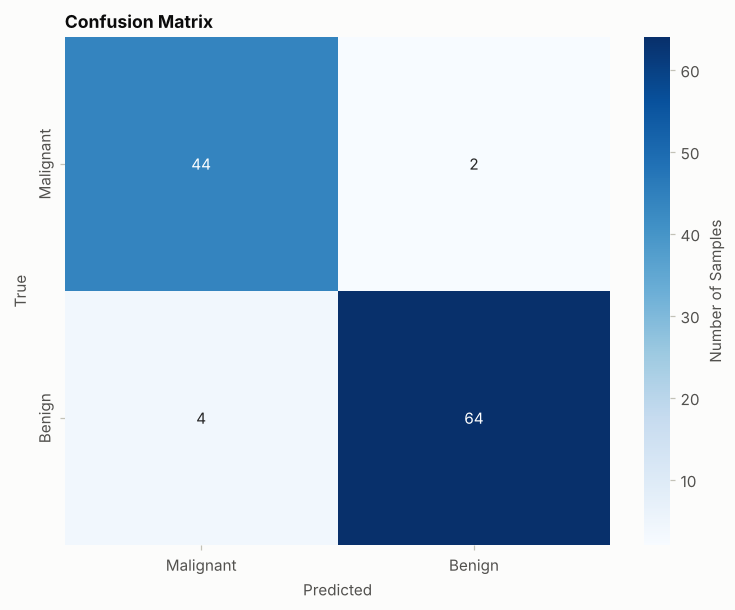

Accuracy: 0.95


Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [3]:
# BOOK CODE: Overview of logistic regression -- how to do it (pp. 125-127)
# Create a logistic regression model
model = LogisticRegression(max_iter=10000)  # Increase max_iter if convergence issues occur

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred)

# Generate and plot a confusion matrix
class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Get a classification report as a dictionary
report_dict = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)

# Create a DataFrame for better visualization
report_df = pd.DataFrame(report_dict).transpose()

# Style the DataFrame
styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f'Accuracy: {accuracy:.2f}\n')
print("\nClassification Report:")
display(styled_df)

**Output analysis.**

* **Accuracy 0.95, as in the book.** The exact value is $108/114 = 0.947$: the 20% test set holds 114 tumours, 46 malignant and 68 benign.
* **The confusion matrix** (rows = truth, columns = prediction):
  * 44 of the 46 malignant tumours are recognized, and **2 malignant tumours are called benign**;
  * 64 of the 68 benign tumours are recognized, and 4 are called malignant.
* **The book's question** — which metric is better than accuracy here? The two kinds of error do not cost the same. Calling a malignant tumour benign (a missed cancer) is far worse than a false alarm, which a biopsy would clear. The metric to watch is therefore the **recall of the malignant class**, also called *sensitivity*: $44/46 = 0.957$ in the "Malignant" row of the report. Its precision (0.917) says how many of the tumours flagged as malignant really are.
* **Macro versus weighted average.** The macro average weighs the two classes equally; the weighted average weighs them by their support (46 and 68). They differ little here because the classes are not very imbalanced.

predict_proba equals sigmoid(decision_function): True
decision_function equals X @ coef_ + intercept_: True
predict equals (log-odds > 0)                  : True


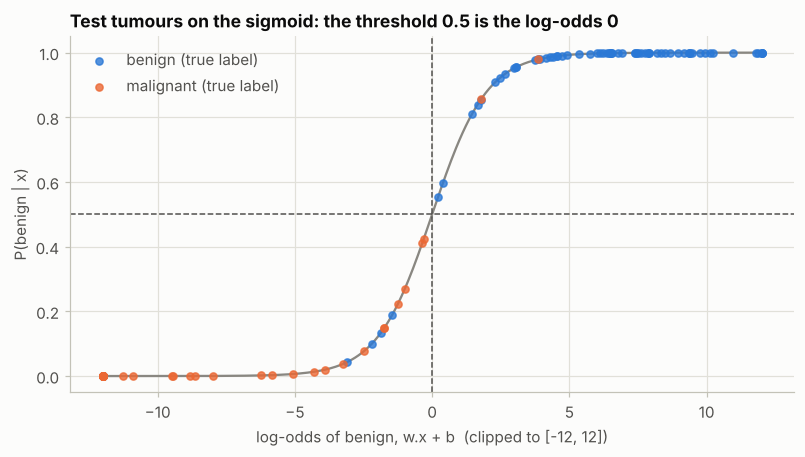

In [4]:
# EXTRA: (a) The fitted model is a sigmoid of a linear score -- checking the formulas on the book's model
scores = model.decision_function(X_test)          # w.x + b, the log-odds of class 1 (benign)
proba_benign = model.predict_proba(X_test)[:, 1]
print("predict_proba equals sigmoid(decision_function):", np.allclose(proba_benign, 1 / (1 + np.exp(-scores))))
print("decision_function equals X @ coef_ + intercept_:",
      np.allclose(scores, X_test.to_numpy() @ model.coef_.ravel() + model.intercept_[0]))
print("predict equals (log-odds > 0)                  :", np.array_equal(y_pred, (scores > 0).astype(int)))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
z = np.linspace(-12, 12, 400)
ax.plot(z, 1 / (1 + np.exp(-z)), color=MUTED, lw=1.5, zorder=1)
for label, name, color in [(1, "benign (true label)", PALETTE[0]), (0, "malignant (true label)", PALETTE[1])]:
    keep = (y_test.to_numpy() == label)
    ax.scatter(np.clip(scores[keep], -12, 12), proba_benign[keep], s=22, color=color, alpha=0.8, label=name,
               zorder=3 if label == 0 else 2)  # malignant on top, so the missed cancers stay visible
ax.axvline(0, color=INK_SOFT, lw=1, ls="--")
ax.axhline(0.5, color=INK_SOFT, lw=1, ls="--")
ax.set_xlabel("log-odds of benign, w.x + b  (clipped to [-12, 12])")
ax.set_ylabel("P(benign | x)")
ax.set_title("Test tumours on the sigmoid: the threshold 0.5 is the log-odds 0")
ax.legend(loc="upper left")
plt.show()

In [5]:
# EXTRA: (b) Maximum likelihood by hand -- Newton's method reproduces scikit-learn's coefficients
from sklearn.preprocessing import StandardScaler

Z_train = StandardScaler().fit_transform(X_train)   # standardized features: a well-conditioned problem
C = 1.0
sk_model = LogisticRegression(C=C, tol=1e-10, max_iter=10000).fit(Z_train, y_train)

# Newton iterations on  C * sum(log-loss) + 0.5 * ||w||^2  (the intercept is not penalized)
A = np.hstack([Z_train, np.ones((len(Z_train), 1))])   # last column = intercept
t = y_train.to_numpy()
theta = np.zeros(A.shape[1])
penalty = np.eye(A.shape[1])
penalty[-1, -1] = 0.0
for iteration in range(1, 51):
    p = 1 / (1 + np.exp(-(A @ theta)))
    gradient = C * A.T @ (p - t) + penalty @ theta
    hessian = C * (A * (p * (1 - p))[:, None]).T @ A + penalty
    step = np.linalg.solve(hessian, gradient)
    theta -= step
    if np.abs(step).max() < 1e-12:
        break

print(f"Newton's method converged in {iteration} iterations")
print(f"largest difference from scikit-learn's coef_     : {np.abs(theta[:-1] - sk_model.coef_.ravel()).max():.1e}")
print(f"difference from scikit-learn's intercept_        : {abs(theta[-1] - sk_model.intercept_[0]):.1e}")

# Odds ratios: the factor by which the odds of "benign" change when a feature rises by one standard deviation
odds_ratios = pd.Series(np.exp(sk_model.coef_.ravel()), index=data.feature_names).sort_values()
print("\nOdds ratios per standard deviation (standardized features, C=1):")
print(pd.concat([odds_ratios.head(4), odds_ratios.tail(3)]).round(3).to_string())

Newton's method converged in 11 iterations
largest difference from scikit-learn's coef_     : 8.3e-07
difference from scikit-learn's intercept_        : 5.8e-08

Odds ratios per standard deviation (standardized features, C=1):
worst texture              0.264
radius error               0.282
worst radius               0.359
worst area                 0.392
mean compactness           1.481
fractal dimension error    1.750
compactness error          1.920


In [6]:
# EXTRA: (c) Why the book needs max_iter=10000 -- feature scales and the solver
from sklearn.pipeline import make_pipeline

scaled_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
print(f"lbfgs iterations on the raw features          : {model.n_iter_[0]:>5}  (default limit: 100)")
print(f"lbfgs iterations on the standardized features : {scaled_model[-1].n_iter_[0]:>5}")
print(f"test accuracy, raw features (book)            : {model.score(X_test, y_test):.3f}")
print(f"test accuracy, standardized features          : {scaled_model.score(X_test, y_test):.3f}")
print("\nfeature ranges:", f"'mean area' up to {X_train['mean area'].max():.0f},",
      f"'mean smoothness' up to {X_train['mean smoothness'].max():.3f}")

lbfgs iterations on the raw features          :  1894  (default limit: 100)
lbfgs iterations on the standardized features :    19
test accuracy, raw features (book)            : 0.947
test accuracy, standardized features          : 0.982

feature ranges: 'mean area' up to 2501, 'mean smoothness' up to 0.163


**Output analysis.**

* **(a)** The three checks print `True`. `predict_proba` is exactly the sigmoid of `decision_function`, which is the linear score $w^\top x + b$, and `predict` returns benign exactly when the log-odds are positive. In the figure every test tumour sits on the sigmoid, and the two misclassification types appear as malignant points to the right of the dashed line and benign points to its left.
* **(b)** Eleven Newton steps reproduce scikit-learn's coefficients to within $10^{-6}$. `LogisticRegression` is nothing more than this penalized log-loss minimized by a numerical solver.
  * The **odds ratios** read directly: one standard deviation more of *worst texture* multiplies the odds of "benign" by 0.26, so it multiplies the odds of malignancy by about 3.8.
  * Size features (*worst radius*, *worst area*) and *radius error* act the same way.
  * Correlated features share their effect, so a single odds ratio should not be read in isolation (recipe 3 shows how Lasso picks among correlated features).
* **(c)** The raw features live on very different scales (areas in the thousands, smoothness around 0.1). `lbfgs` then needs **1,894 iterations**, which is why the book raises `max_iter` to 10,000. After standardization it converges in 19.
  * Scaling also changes the *model*, not only the speed. The $L_2$ penalty $\tfrac12\lVert w\rVert^2$ treats every coefficient alike, which is only fair when the features share a scale.
  * On this split the standardized model makes 2 errors instead of 6 (accuracy 0.982 instead of 0.947).

---
## 2. Multiclass classification techniques

### Summary

* Outcomes are not always binary, and logistic regression extends to more than two classes in two ways:
  * **one-vs-rest (OvR)**, also called one-vs-all;
  * **multinomial** (softmax) logistic regression.
* **Getting ready** — the Iris dataset (three classes), split 70/30 with `random_state=2024`. The listing also imports `DecisionBoundaryDisplay`, but never uses it.
* **How to do it:**
  * Fit `LogisticRegression(solver='liblinear')` as the OvR model.
  * Fit `LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)` as the multinomial model.
  * Show both classification reports as styled DataFrames (Figures 6.3 and 6.4).
  * The book notes that `multi_class` is removed after scikit-learn 1.7, when the multinomial option is always used for three or more classes.
  * It explains that the macro average weighs the classes equally while the weighted average weighs them by their support.
* **How it works:**
  * **OvR** trains one binary classifier per class (that class against all others) and predicts the class whose classifier is most confident.
  * **Multinomial** logistic regression ("softmax regression") models all class probabilities together with the softmax function. It is "more suitable when the classes are mutually exclusive".
  * Key considerations:
    * the solver (`liblinear` for OvR, `lbfgs` or `newton-cg` for multinomial);
    * regularization;
    * scaling the features.
* **There's more** — a seaborn **pairplot** of the Iris features coloured by species (Figure 6.5). The book reads high kurtosis in petal length and petal width, and takes it as a sign that these features are valuable.
* **Hands-on** — the steps include decision boundary plots for both models, which extra (c) draws.

### Theory: one-vs-rest, softmax, and what changed in scikit-learn

**One-vs-rest.** With $K$ classes, OvR fits $K$ independent binary logistic regressions, each separating class $k$ from the other classes, with scores $s_k(x) = w_k^\top x + b_k$. The prediction is $\arg\max_k s_k(x)$. The $K$ sigmoids do not sum to one, so OvR probabilities are obtained by normalizing them: a convenient rescaling, not a probability model.

**Multinomial (softmax) regression.** One model gives all class probabilities at once:

$$
P(y = k \mid x) = \frac{\exp(w_k^\top x + b_k)}{\sum_{j=1}^{K} \exp(w_j^\top x + b_j)} ,
$$

fitted by minimizing the multiclass cross-entropy $-\sum_i \log P(y_i \mid x_i)$, plus the penalty. Adding the same vector to every $w_k$ leaves the probabilities unchanged. With an $L_2$ penalty the minimizer is the symmetric solution, in which the class coefficient vectors sum to zero. Extra (b) checks both the softmax formula and this property.

**Which one?** The multinomial model fits the classes jointly and gives coherent probabilities. OvR fits easier, independent problems, and is what remains when a solver only handles two classes (like `liblinear`). A third strategy, **one-vs-one** (`OneVsOneClassifier`), fits $K(K-1)/2$ pairwise models and lets them vote.

**What changed since the book (scikit-learn 1.5).**

| Book code | scikit-learn 1.5 to 1.7 | scikit-learn 1.8 and later |
|---|---|---|
| `LogisticRegression(multi_class='multinomial', ...)` | works, with a `FutureWarning` (deprecated in 1.5) | **removed**: `TypeError` |
| `LogisticRegression(solver='liblinear')` on 3 classes | one-vs-rest, with a `FutureWarning` | **`ValueError`** |

With three or more classes, every solver except `liblinear` fits the multinomial model; since 1.8 there is no option to change that. The OvR behaviour is obtained explicitly with `OneVsRestClassifier(LogisticRegression(solver='liblinear'))`, which is what the old internal OvR did. The listing below makes these two replacements, keeps the book's lines as comments, and extra (a) shows the errors.

**Averages in the classification report.** For each class, precision, recall and F1 are computed one class against the others. The **macro average** is their plain mean over classes, and the **weighted average** weighs them by support. For a single-label problem, the overall *accuracy* row equals the micro average.

In [7]:
# BOOK CODE: Multiclass classification techniques -- getting ready (p. 130)
# Load the libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report)
from sklearn.inspection import DecisionBoundaryDisplay
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [8]:
# BOOK CODE: Multiclass classification techniques -- how to do it (pp. 131-133)
# Adapted for scikit-learn >= 1.8 (see the theory section and extra (a)):
from sklearn.multiclass import OneVsRestClassifier

# Create and train an OvR logistic regression model
# Book: ovr_model = LogisticRegression(solver='liblinear')  -> ValueError for 3 classes since scikit-learn 1.8
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(X_train, y_train)

# Create and train a multinomial logistic regression model
# Book: LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)  -> multi_class removed in 1.8
multinomial_model = LogisticRegression(
    solver='lbfgs', max_iter = 1000
)
multinomial_model.fit(X_train, y_train)

# Make predictions with the OvR model
y_pred_ovr = ovr_model.predict(X_test)

# Make predictions with the multinomial model
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluate the OvR model
accuracy_ovr = accuracy_score(y_test, y_pred_ovr)
report_ovr = pd.DataFrame(classification_report(
    y_test, y_pred_ovr, output_dict=True)).transpose()
print("One-vs-Rest (OvR) Logistic Regression:")
styled_ovr = (report_ovr
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovr)

# Evaluate the multinomial model
accuracy_multinomial = accuracy_score(
    y_test, y_pred_multinomial)
report_multinomial = pd.DataFrame(classification_report(
    y_test, y_pred_multinomial,
    output_dict=True)).transpose()
print("Multinomial Logistic Regression:")
styled_multinomial = (report_multinomial
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_multinomial)

One-vs-Rest (OvR) Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


Multinomial Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


In [9]:
# EXTRA: (a) The book's two original lines on the installed scikit-learn
attempts = {
    "LogisticRegression(solver='liblinear')": lambda: LogisticRegression(solver='liblinear'),
    "LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)":
        lambda: LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000),
}
for text, make in attempts.items():
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            make().fit(X_train, y_train)
        note = f"runs ({caught[0].category.__name__})" if caught else "runs"
        print(f"{text}\n    {note}")
    except (TypeError, ValueError) as error:
        print(f"{text}\n    {type(error).__name__}: {error}")

# The confusion matrices behind the two reports (rows = true class, columns = prediction)
from sklearn.metrics import confusion_matrix
for name, pred in [("OvR", y_pred_ovr), ("multinomial", y_pred_multinomial)]:
    print(f"\n{name}: accuracy {accuracy_score(y_test, pred):.3f} ({(pred == y_test).sum()} of {len(y_test)})")
    print(pd.DataFrame(confusion_matrix(y_test, pred), index=iris.target_names, columns=iris.target_names))

LogisticRegression(solver='liblinear')
    ValueError: The 'liblinear' solver does not support multiclass classification (n_classes >= 3). Either use another solver or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
    TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

OvR: accuracy 0.956 (43 of 45)
            setosa  versicolor  virginica
setosa          18           0          0
versicolor       0          11          1
virginica        0           1         14

multinomial: accuracy 0.933 (42 of 45)
            setosa  versicolor  virginica
setosa          18           0          0
versicolor       0          11          1
virginica        0           2         13


**Output analysis.**

* **The book's lines no longer run.** On scikit-learn 1.9, `liblinear` refuses three classes (`ValueError`, with the advice to use `OneVsRestClassifier`), and `multi_class` is an unknown argument (`TypeError`). With the two replacements, the models are the ones the book fitted on scikit-learn 1.5.
* **The two reports** (45 test flowers: 18 setosa, 12 versicolor, 15 virginica):
  * **OvR** gets 43 of 45 right (accuracy 0.956); **multinomial** gets 42 (0.933).
  * Setosa is always perfect, and every error confuses versicolor with virginica.
  * A difference of one flower on 45 is not evidence that OvR is better; extra (d) measures the difference properly.
* **Precisions to the text:**
  * The figure introduced as "our confusion matrix for OvR classification" is the classification report; the confusion matrices are printed above.
  * The text calls the macro average "macro accuracy". It is the macro average of precision, recall and F1.
  * The second model is described as "multinomial classification for a binary classification problem"; Iris has three classes.
* **Macro versus weighted:** the averages are close (OvR F1 0.950 versus 0.956; multinomial 0.926 versus 0.934) because the three classes have similar support.

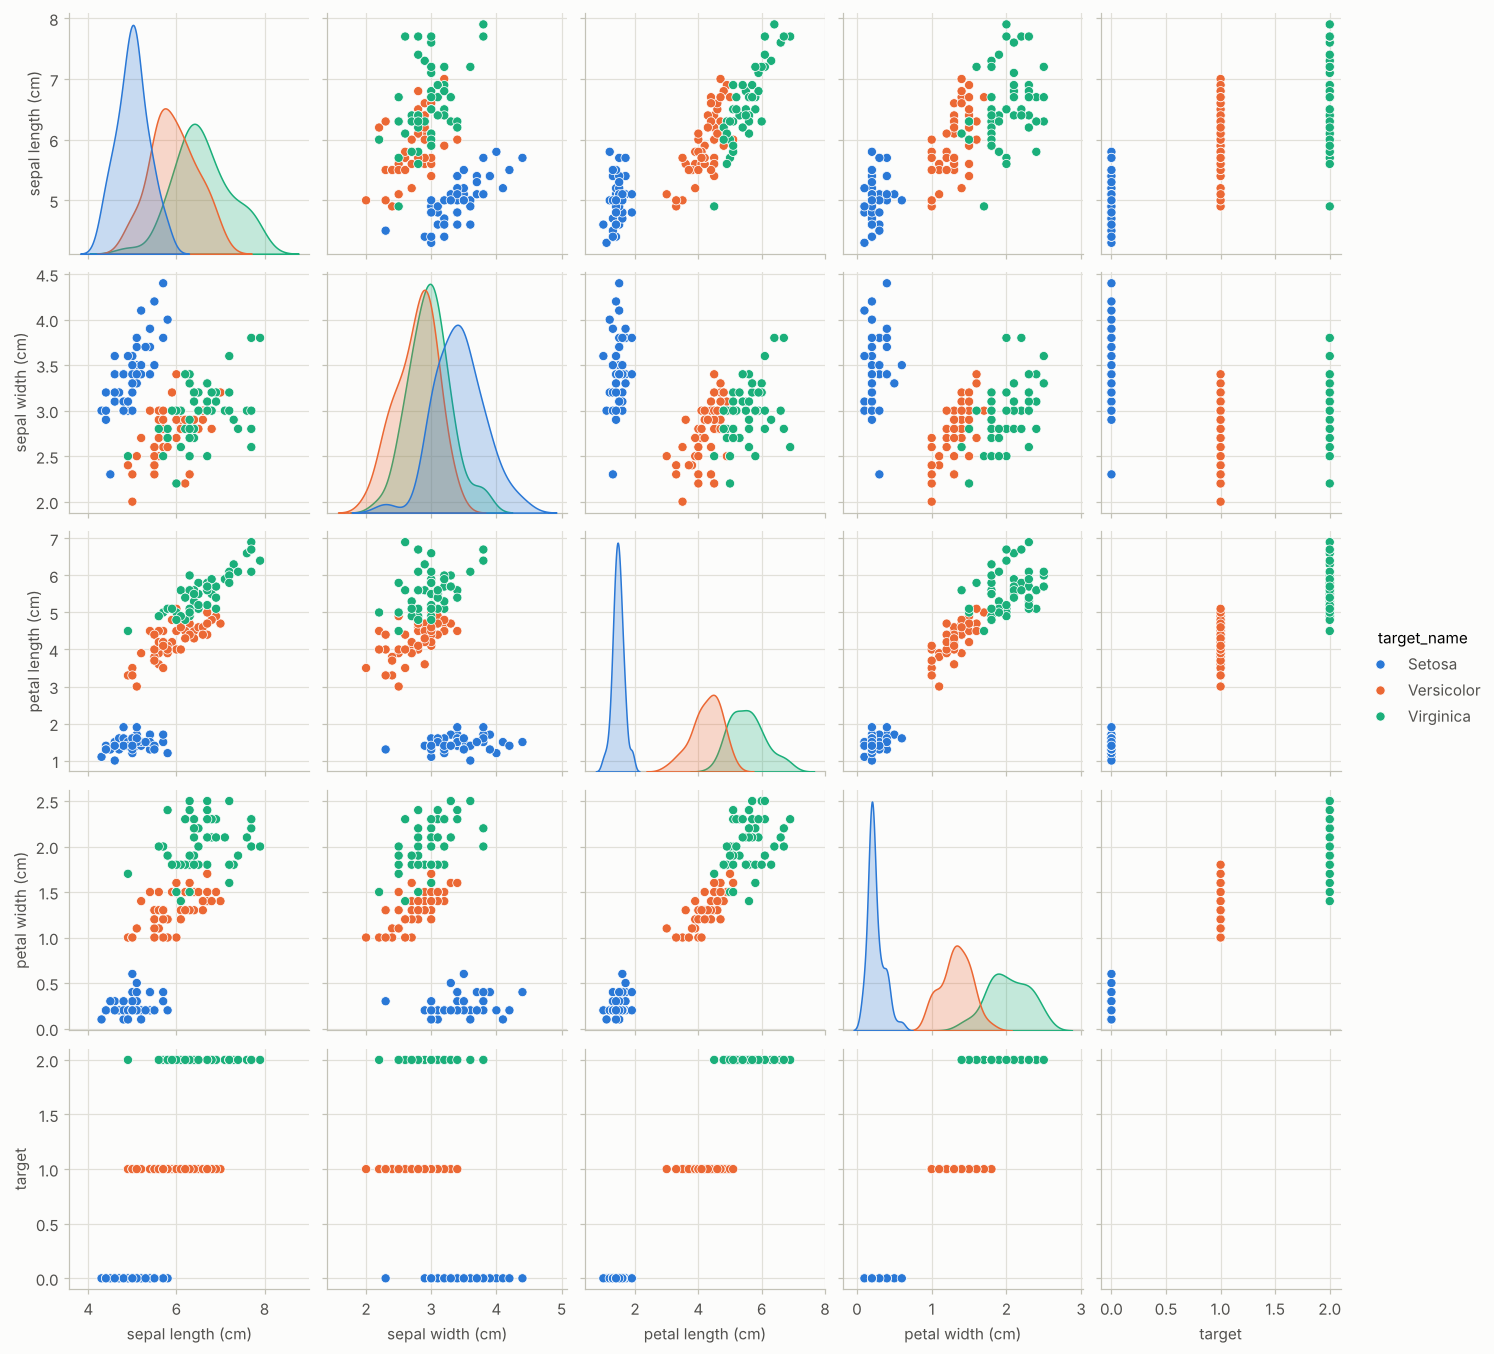

In [10]:
# BOOK CODE: Multiclass classification techniques -- there's more: pairplot (p. 134)
# Create a pairplot to visualize the data
target_names = {0: 'Setosa',
                1: 'Versicolor',
                2: 'Virginica'}
df['target_name'] = df['target'].map(target_names)
sns.pairplot(df, hue='target_name', diag_kind='kde')
plt.show()

In [11]:
# EXTRA: (b) The pairplot's message in numbers -- kurtosis versus class separation
from scipy import stats
from sklearn.feature_selection import f_classif

F, _ = f_classif(iris.data, iris.target)
summary = pd.DataFrame({
    "excess kurtosis (all flowers)": [stats.kurtosis(iris.data[:, j]) for j in range(4)],
    "excess kurtosis (setosa only)": [stats.kurtosis(iris.data[iris.target == 0, j]) for j in range(4)],
    "ANOVA F (between / within classes)": F,
}, index=feature_names).round(2)
print(summary.to_string())

                   excess kurtosis (all flowers)  excess kurtosis (setosa only)  ANOVA F (between / within classes)
sepal length (cm)                          -0.57                          -0.35                              119.26
sepal width (cm)                            0.18                           0.74                               49.16
petal length (cm)                          -1.40                           0.80                             1180.16
petal width (cm)                           -1.34                           1.43                              960.01


**Output analysis.**

* **The grid is 5 by 5, not 4 by 4.** `df` still holds the numeric `target` column, so seaborn plots it as a fifth "feature". Its row and column only show the class codes 0, 1 and 2.
* **What the figure shows:**
  * Petal length and petal width separate setosa completely from the other two species.
  * Versicolor and virginica overlap only slightly on the petal features, and much more on the sepal features.
* **About kurtosis.** The book reads the petal distributions as having "high kurtosis (narrow, peaked)". Over all flowers the opposite is true:
  * The excess kurtosis is **−1.40** for petal length and **−1.34** for petal width: flatter than a normal distribution, because the distribution is bimodal (setosa versus the rest).
  * Only *within* setosa are the petal features peaked (0.80 and 1.43).
  * What makes a feature valuable for classification is the **separation between the classes** relative to the spread within them. The ANOVA $F$ statistic measures exactly that: **1,180** and **960** for the petal features, against 119 and 49 for the sepal features.

predict_proba equals the softmax of X @ coef_.T + intercept_: True
sum of the three class coefficient vectors: [0. 0. 0. 0.] | sum of intercepts: 0.0


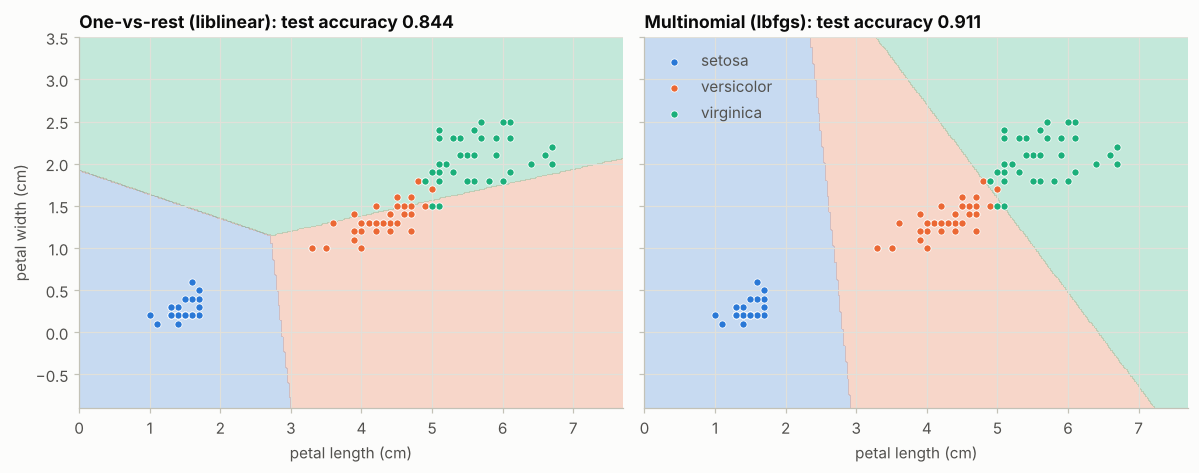

In [12]:
# EXTRA: (c) Softmax by hand, and the symmetric coefficients of the multinomial model
W, b = multinomial_model.coef_, multinomial_model.intercept_
scores = X_test @ W.T + b
softmax = np.exp(scores - scores.max(axis=1, keepdims=True))
softmax /= softmax.sum(axis=1, keepdims=True)
print("predict_proba equals the softmax of X @ coef_.T + intercept_:",
      np.allclose(softmax, multinomial_model.predict_proba(X_test)))
print("sum of the three class coefficient vectors:", np.round(W.sum(axis=0), 10), "| sum of intercepts:", round(b.sum(), 10))

# Decision boundaries on the two petal features (the hands-on step 9), with DecisionBoundaryDisplay
import inspect
from matplotlib.colors import ListedColormap

# scikit-learn >= 1.7 colours multiclass regions with multiclass_colors (cmap is ignored there)
if "multiclass_colors" in inspect.signature(DecisionBoundaryDisplay.from_estimator).parameters:
    region_colors = {"multiclass_colors": PALETTE}
else:
    region_colors = {"cmap": ListedColormap(PALETTE)}
petal = [2, 3]
models_2d = {
    "One-vs-rest (liblinear)": OneVsRestClassifier(LogisticRegression(solver='liblinear')),
    "Multinomial (lbfgs)": LogisticRegression(max_iter=1000),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (title, clf) in zip(axes, models_2d.items()):
    clf.fit(X_train[:, petal], y_train)
    DecisionBoundaryDisplay.from_estimator(
        clf, X_train[:, petal], response_method="predict", ax=ax, alpha=0.25,
        grid_resolution=300, **region_colors)
    for k, color in enumerate(PALETTE):
        keep = y_train == k
        ax.scatter(X_train[keep, 2], X_train[keep, 3], s=22, color=color, edgecolor="white", lw=0.5,
                   label=iris.target_names[k])
    acc = clf.score(X_test[:, petal], y_test)
    ax.set_title(f"{title}: test accuracy {acc:.3f}")
    ax.set_xlabel(feature_names[2])
axes[0].set_ylabel(feature_names[3])
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

In [13]:
# EXTRA: (d) OvR versus multinomial measured properly -- 100 cross-validation folds and the log-loss
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import log_loss

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0)
for name, estimator in [("OvR (liblinear)", OneVsRestClassifier(LogisticRegression(solver='liblinear'))),
                        ("multinomial (lbfgs)", LogisticRegression(max_iter=1000))]:
    scores_cv = cross_val_score(estimator, iris.data, iris.target, cv=cv)
    print(f"{name:20s}: mean accuracy {scores_cv.mean():.3f} (std {scores_cv.std():.3f}) over {len(scores_cv)} folds")

print(f"\nlog-loss on the book's test set: OvR {log_loss(y_test, ovr_model.predict_proba(X_test)):.3f}, "
      f"multinomial {log_loss(y_test, multinomial_model.predict_proba(X_test)):.3f}")

OvR (liblinear)     : mean accuracy 0.958 (std 0.032) over 100 folds
multinomial (lbfgs) : mean accuracy 0.964 (std 0.035) over 100 folds

log-loss on the book's test set: OvR 0.320, multinomial 0.173


**Output analysis.**

* **(c)** `predict_proba` is exactly the softmax of the three linear scores. The three coefficient vectors sum to zero, as do the intercepts: the $L_2$ penalty picks the symmetric solution among the equivalent parametrizations.
  * The figure shows the boundaries on the two petal features. Both models draw straight boundaries (linear in the log-odds), but OvR places its regions differently.
  * Versicolor lies *between* the other two species, so no single line separates it from both. OvR's versicolor-against-the-rest model is therefore weak, and the argmax of three independently fitted models gives distorted regions. This "masking" of a middle class is a known weakness of OvR.
  * On these two features the multinomial model scores **0.911** on the test set against **0.844** for OvR.
* **(d)** Over 100 folds the multinomial model is slightly *better* on average (0.964 against 0.958), and both standard deviations (about 0.03) are larger than the difference: the two strategies are equally accurate on Iris.
  * The real difference is in the **probabilities**: the multinomial model's log-loss on the test set (0.173) is about half of OvR's (0.320). Normalized OvR sigmoids are less confident and less coherent than a softmax fitted jointly.

---
## 3. Regularization in logistic regression

### Summary

* Regularization prevents overfitting, especially with many features. This recipe applies the **ridge ($L_2$)** and **Lasso ($L_1$)** penalties of Chapter 5 to logistic regression, and tunes their strength to balance bias and variance.
* **Getting ready** — the Breast Cancer data again, split 70/30 (`random_state=2024`) and standardized with `StandardScaler` (fitted on the training set).
* **How to do it:**
  * Fit `LogisticRegression(penalty='l2', solver='liblinear', C=0.1)` and `LogisticRegression(penalty='l1', solver='liblinear', C=0.1)`.
  * Show their classification reports (Figures 6.6 and 6.7).
  * The book's reading: Lasso has a slightly lower accuracy, but "ridge outperforms in precision while Lasso outperforms in recall".
* **How it works:**
  * $L_2$ shrinks the coefficients toward zero but rarely to exactly zero.
  * $L_1$ drives some to exactly zero (feature selection).
  * `C` is the **inverse** of the regularization strength.
  * Key considerations:
    * `liblinear` supports both penalties on small datasets, and `saga` suits larger ones;
    * scale the features;
    * tune `C` with grid or random search.
* **There's more** — the coefficients plotted against `C` from $10^{-4}$ to $10^{3}$ for both penalties (Figures 6.8 and 6.9).

### Theory: penalized likelihood, `C`, and the solvers

**The objectives.** With $\ell_i$ the log-loss of sample $i$ (recipe 1), scikit-learn solves

$$
\text{ridge: } \min_{w,b}\; C \sum_{i=1}^{n} \ell_i(w, b) + \tfrac{1}{2}\lVert w \rVert_2^2, \qquad
\text{Lasso: } \min_{w,b}\; C \sum_{i=1}^{n} \ell_i(w, b) + \lVert w \rVert_1 .
$$

Dividing by $C$ shows that $1/C$ plays the role of the penalty weight $\lambda$ (or `alpha` in Chapter 5). Small `C` means strong regularization, and large `C` approaches the unpenalized maximum likelihood fit.

**Why $L_1$ gives zeros.** As in Chapter 5, the $L_1$ ball has corners on the axes, so the penalized optimum often lies where some coefficients are exactly zero. In the coordinate-wise optimality conditions, a coefficient stays at zero as long as the gradient of $C\sum_i \ell_i$ with respect to it is smaller than 1 in absolute value. As `C` grows, more coefficients pass that threshold and enter the model one by one.

**Elastic net and the new API.** The mixed penalty $\rho \lVert w\rVert_1 + \frac{1-\rho}{2} \lVert w\rVert_2^2$ is available with the `saga` solver, where $\rho$ is `l1_ratio`.

* scikit-learn 1.8 made `l1_ratio` the only switch between penalties: `l1_ratio=0` is ridge, `l1_ratio=1` is Lasso, values in between are elastic net, and `C=np.inf` removes the penalty.
* The `penalty` argument is deprecated (removed in 1.10). The book's `penalty='l1'` still works on 1.9, with a `FutureWarning` and a second warning about the "inconsistent" default `l1_ratio=0`. The setup cell silences both, and extra (a) shows that the models are identical.

**Which solver supports what.**

| Solver | Penalties | Notes |
|---|---|---|
| `lbfgs` (default), `newton-cg`, `newton-cholesky`, `sag` | $L_2$ or none | multinomial for 3 or more classes |
| `liblinear` | $L_1$, $L_2$ | binary only (wrap in `OneVsRestClassifier`); **also penalizes the intercept** |
| `saga` | $L_1$, $L_2$, elastic net | suited to large datasets; needs scaled features to converge fast |

`liblinear` treats the intercept as the coefficient of a constant feature (`intercept_scaling`), so it shrinks the intercept too. On standardized features this matters little.

**Scaling** matters for the same reason as in Chapter 5: the penalty treats all coefficients alike, so features must share a scale for the penalty to be fair. The book standardizes in this recipe, but not in recipe 5 or in the exercises.

**A Bayesian reading.** Minimizing log-loss plus penalty is maximum *a posteriori* estimation: the $L_2$ penalty corresponds to a Gaussian prior on the coefficients, and the $L_1$ penalty to a Laplace prior, whose peak at zero favours exact zeros.

In [14]:
# BOOK CODE: Regularization in logistic regression -- getting ready (pp. 136-137)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report)
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset and scale it
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
# BOOK CODE: Regularization in logistic regression -- how to do it (pp. 137-139)
# Create and train a Ridge (L2) regularized logistic regression model
ridge_model = LogisticRegression(
    penalty='l2', solver='liblinear', C=0.1)
ridge_model.fit(X_train, y_train)

# Create and train a Lasso (L1) regularized logistic regression model
lasso_model = LogisticRegression(
    penalty='l1', solver='liblinear', C=0.1)
lasso_model.fit(X_train, y_train)

# Make predictions with the Ridge model
y_pred_ridge = ridge_model.predict(X_test)

# Make predictions with the Lasso model
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the Ridge model
accuracy_ridge = accuracy_score(y_test, y_pred_ridge)
report_ridge = pd.DataFrame(classification_report(
    y_test, y_pred_ridge, output_dict=True)).transpose()
print("Ridge (L2) Regularized Logistic Regression:")
styled_ridge = (report_ridge
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ridge)

# Evaluate the Lasso model
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
report_lasso = pd.DataFrame(classification_report(
    y_test, y_pred_lasso, output_dict=True)).transpose()
print("Lasso (L1) Regularized Logistic Regression:")
styled_lasso = (report_lasso
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_lasso)

Ridge (L2) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


Lasso (L1) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


In [16]:
# EXTRA: (a) The book's penalty= calls and the l1_ratio API give the same models
from sklearn.metrics import confusion_matrix

if sk_version >= (1, 8):
    for book_kwargs, new_kwargs in [({"penalty": "l2"}, {"l1_ratio": 0.0}), ({"penalty": "l1"}, {"l1_ratio": 1.0})]:
        old = LogisticRegression(**book_kwargs, solver='liblinear', C=0.1, random_state=0).fit(X_train, y_train)
        new = LogisticRegression(**new_kwargs, solver='liblinear', C=0.1, random_state=0).fit(X_train, y_train)
        print(f"{book_kwargs} vs {new_kwargs}: identical coefficients -> {np.array_equal(old.coef_, new.coef_)}")
else:
    print("scikit-learn < 1.8: penalty= is the current API, nothing to compare")

# liblinear's L1 solver is randomized: without random_state, two fits differ slightly
fit_a = LogisticRegression(**L1, solver='liblinear', C=0.1, random_state=0).fit(X_train, y_train)
fit_b = LogisticRegression(**L1, solver='liblinear', C=0.1, random_state=1).fit(X_train, y_train)
print(f"\nL1 fits with two different seeds: largest coefficient difference {np.abs(fit_a.coef_ - fit_b.coef_).max():.3f}, "
      f"same predictions -> {np.array_equal(fit_a.predict(X_test), fit_b.predict(X_test))}")

for name, pred in [("ridge (L2)", y_pred_ridge), ("Lasso (L1)", y_pred_lasso)]:
    (tn_m, fp_m), (fn_m, tp_m) = confusion_matrix(y_test, pred)
    print(f"{name}: accuracy {accuracy_score(y_test, pred):.3f} | malignant called benign: {fp_m} | benign called malignant: {fn_m}")

{'penalty': 'l2'} vs {'l1_ratio': 0.0}: identical coefficients -> True
{'penalty': 'l1'} vs {'l1_ratio': 1.0}: identical coefficients -> True

L1 fits with two different seeds: largest coefficient difference 0.011, same predictions -> True
ridge (L2): accuracy 0.982 | malignant called benign: 2 | benign called malignant: 1
Lasso (L1): accuracy 0.965 | malignant called benign: 1 | benign called malignant: 5


**Output analysis.**

* **(a)** The book's `penalty='l2'` and `penalty='l1'` calls give exactly the coefficients of `l1_ratio=0` and `l1_ratio=1` (same seed). `liblinear`'s $L_1$ solver is randomized: two seeds change the coefficients by up to about 0.01, without changing a single prediction. The setup cell's global seed makes the notebook reproducible.
* **Accuracy:** ridge reaches **0.982** (3 errors out of 171) and Lasso **0.965** (6 errors). As the book says, Lasso is slightly less accurate.
* **"Ridge outperforms in precision while Lasso outperforms in recall"** holds for the **malignant** class (row `0`):

  | Malignant class | Precision | Recall |
  |---|---|---|
  | ridge | 0.985 | 0.970 |
  | Lasso | 0.930 | 0.985 |

  For the benign class (row `1`) the roles are reversed: Lasso has the higher precision (0.990 versus 0.981) and ridge the higher recall (0.990 versus 0.952).
  * This is unavoidable with two classes. Lasso calls 5 benign tumours malignant, which lowers both the malignant precision and the benign recall.
  * It misses only 1 malignant tumour, against 2 for ridge.
  * For cancer screening, Lasso's errors are the cheaper kind.

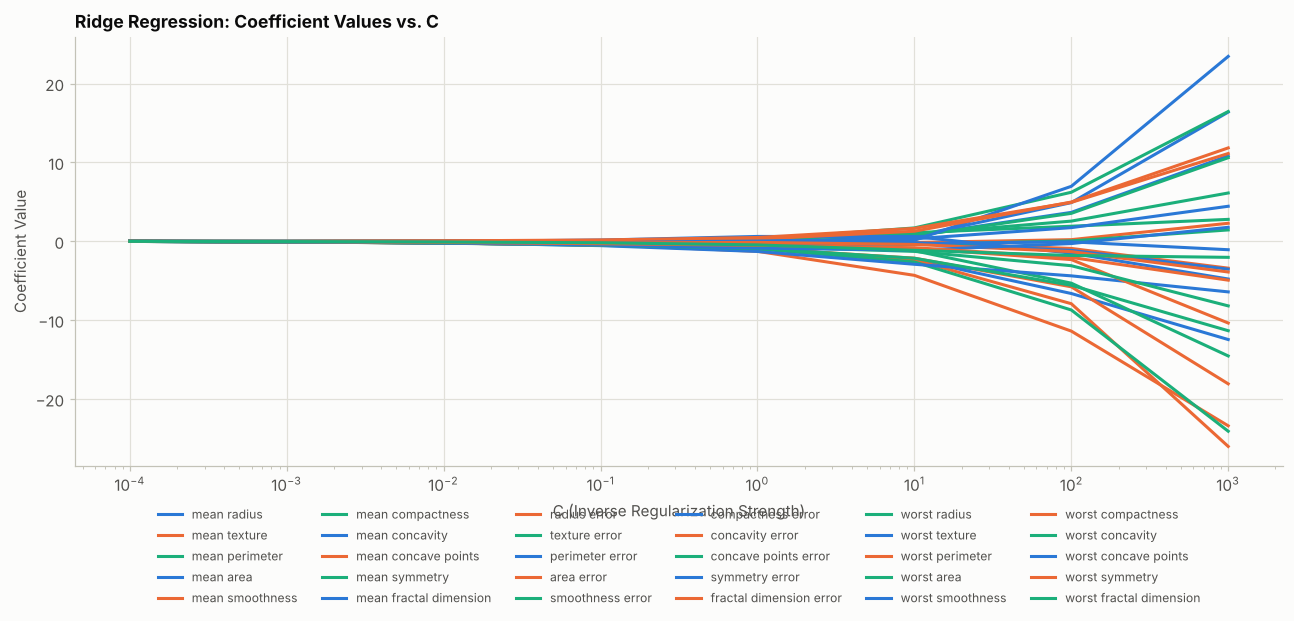

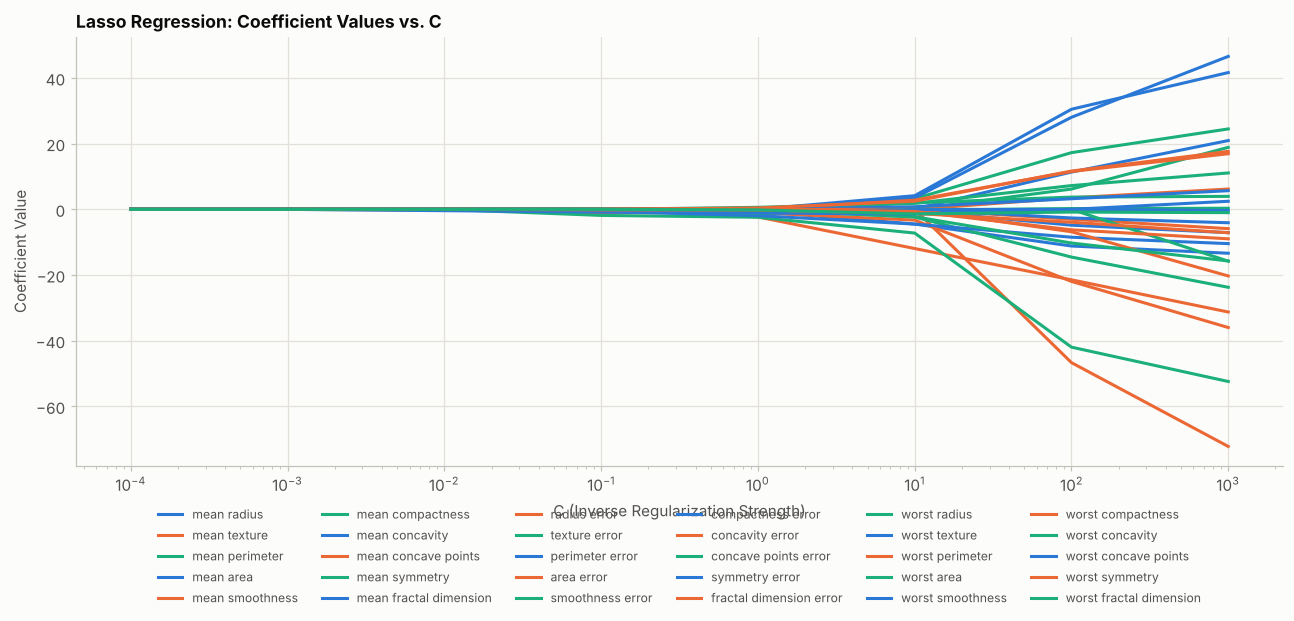

In [17]:
# BOOK CODE: Regularization in logistic regression -- there's more: coefficients against C (pp. 140-142)
# Plot coefficients for different C values (Ridge)
C_values = np.array(
    [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_ridge = []
for C in C_values:
    ridge_model = LogisticRegression(
        penalty='l2', solver='liblinear', C=C)
    ridge_model.fit(X_train, y_train)
    coefs_ridge.append(ridge_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(
        C_values, [coef[i] for coef in coefs_ridge],
        label=feature_names[i]
    )
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Ridge Regression: Coefficient Values vs. C')
plt.legend(
    bbox_to_anchor=(0.5, -0.35),
    ncol=6, loc='lower center', fontsize=8
)
plt.tight_layout()
plt.show()

# Plotting coefficients for different C values (Lasso)
C_values = np.array(
    [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_lasso = []
for C in C_values:
    lasso_model = LogisticRegression(
        penalty='l1', solver='liblinear', C=C)
    lasso_model.fit(X_train, y_train)
    coefs_lasso.append(lasso_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(
        C_values, [coef[i] for coef in coefs_lasso],
        label=feature_names[i]
    )
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Regression: Coefficient Values vs. C')
plt.legend(
    bbox_to_anchor=(0.5, -0.35), ncol=6,
    loc='lower center', fontsize=8
)
plt.tight_layout()
plt.show()

In [18]:
# EXTRA: (b) Which features Lasso keeps at C=0.1, and what ridge does with correlated features
lasso_01 = LogisticRegression(**L1, solver='liblinear', C=0.1).fit(X_train, y_train)
ridge_01 = LogisticRegression(**L2, solver='liblinear', C=0.1).fit(X_train, y_train)
kept = pd.Series(lasso_01.coef_[0], index=feature_names)
kept = kept[kept != 0].sort_values()
print(f"Lasso (C=0.1) keeps {len(kept)} of {len(feature_names)} features:")
print(kept.round(3).to_string())
print("\nRidge (C=0.1), five largest |coefficients|:")
print(pd.Series(np.abs(ridge_01.coef_[0]), index=feature_names).sort_values().tail(5).round(3).to_string())

size_features = ['mean radius', 'mean perimeter', 'mean area', 'worst radius', 'worst perimeter', 'worst area']
corr = df[size_features].corr().to_numpy()
print(f"\ncorrelations among the six size features: from {corr[np.triu_indices(6, 1)].min():.2f} to {corr[np.triu_indices(6, 1)].max():.3f}")

# Number of non-zero Lasso coefficients and largest ridge coefficient along the book's C grid
nonzero = [int(np.count_nonzero(c)) for c in coefs_lasso]
largest = [float(np.abs(c).max()) for c in coefs_ridge]
print("\n" + pd.DataFrame({"C": C_values, "Lasso: non-zero coefficients": nonzero,
                           "ridge: largest |coefficient|": np.round(largest, 2)}).to_string(index=False))

Lasso (C=0.1) keeps 7 of 30 features:
worst radius           -1.844
mean concave points    -0.998
worst concave points   -0.821
worst texture          -0.621
worst symmetry         -0.155
worst smoothness       -0.040
worst concavity        -0.024

Ridge (C=0.1), five largest |coefficients|:
worst concave points    0.454
worst perimeter         0.465
worst area              0.478
worst radius            0.504
worst texture           0.546

correlations among the six size features: from 0.94 to 0.998

        C  Lasso: non-zero coefficients  ridge: largest |coefficient|
   0.0001                             0                          0.01
   0.0010                             0                          0.08
   0.0100                             2                          0.23
   0.1000                             7                          0.55
   1.0000                            15                          1.29
  10.0000                            23                          4.31
 100

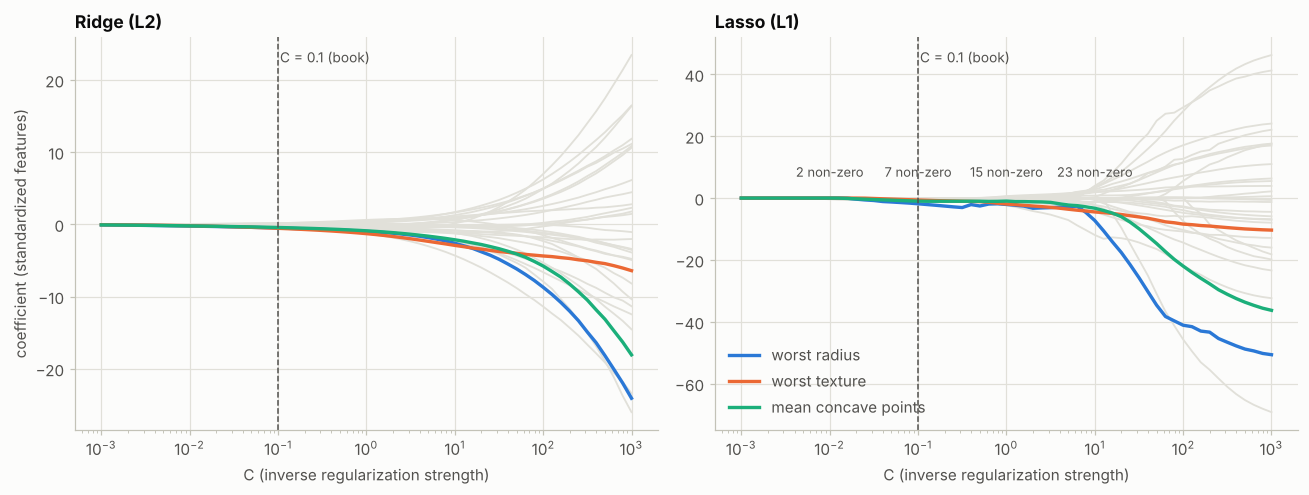

In [19]:
# EXTRA: (c) Readable coefficient paths -- all 30 features in grey, three highlighted, on a fine grid of C
C_fine = np.logspace(-3, 3, 61)
paths = {}
for name, kwargs in [("Ridge (L2)", L2), ("Lasso (L1)", L1)]:
    paths[name] = np.array([LogisticRegression(**kwargs, solver='liblinear', C=c, random_state=0)
                            .fit(X_train, y_train).coef_[0] for c in C_fine])

highlight = ['worst radius', 'worst texture', 'mean concave points']
index = [list(feature_names).index(f) for f in highlight]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, (name, coefs) in zip(axes, paths.items()):
    for j in range(coefs.shape[1]):
        if j not in index:
            ax.plot(C_fine, coefs[:, j], color=GRID, lw=1.2, zorder=1)
    for j, color in zip(index, PALETTE):
        ax.plot(C_fine, coefs[:, j], color=color, lw=2.2, zorder=2, label=feature_names[j])
    ax.axvline(0.1, color=INK_SOFT, lw=1, ls="--")
    ax.text(0.105, 0.97, "C = 0.1 (book)", transform=ax.get_xaxis_transform(), color=INK_SOFT, va="top", fontsize=9)
    ax.set_xscale("log")
    ax.set_xlabel("C (inverse regularization strength)")
    ax.set_title(name)
axes[0].set_ylabel("coefficient (standardized features)")
axes[1].legend(loc="lower left")
nnz = (paths["Lasso (L1)"] != 0).sum(axis=1)
for c in [0.01, 0.1, 1, 10]:
    k = np.argmin(np.abs(C_fine - c))
    axes[1].annotate(f"{nnz[k]} non-zero", (C_fine[k], 0), xytext=(0, 14), textcoords="offset points",
                     ha="center", fontsize=8.5, color=INK_SOFT)
plt.tight_layout()
plt.show()

In [20]:
# EXTRA: (d) Choosing C by cross-validation (scaler inside the pipeline, training set only)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(data.data, data.target, test_size=0.3, random_state=2024)
grid_C = {"logisticregression__C": np.logspace(-3, 3, 13)}
for name, kwargs in [("ridge (L2)", L2), ("Lasso (L1)", L1)]:
    search = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(**kwargs, solver='liblinear', random_state=0)),
                          grid_C, cv=StratifiedKFold(10, shuffle=True, random_state=0))
    search.fit(X_train_raw, y_train_raw)
    best = search.best_estimator_[-1]
    print(f"{name:11s}: best C = {search.best_params_['logisticregression__C']:.4g}, "
          f"CV accuracy {search.best_score_:.3f}, test accuracy {search.score(X_test_raw, y_test_raw):.3f}, "
          f"non-zero coefficients {np.count_nonzero(best.coef_)}")

ridge (L2) : best C = 0.03162, CV accuracy 0.977, test accuracy 0.953, non-zero coefficients 30
Lasso (L1) : best C = 0.3162, CV accuracy 0.977, test accuracy 0.977, non-zero coefficients 10


**Output analysis.**

* **The book's two figures** show the expected shapes, but 30 lines that share a few colours (three in this notebook's plotting style, ten with Matplotlib's defaults), with a 30-entry legend, cannot be told apart:
  * **ridge** (Figure 6.8): every coefficient grows smoothly as `C` increases. The largest one rises from 0.01 at $C = 10^{-4}$ to 26 at $C = 1000$.
  * **Lasso** (Figure 6.9): the coefficients stay at zero until `C` is large enough, then enter one by one: 0, 0, 2, 7, 15, 23, 27 and 30 non-zero coefficients along the book's grid.
* **(b) What Lasso keeps at `C = 0.1`.** 7 of the 30 features:
  * *worst radius* (−1.84), *mean concave points* (−1.00), *worst concave points* (−0.82) and *worst texture* (−0.62);
  * three small ones: *worst symmetry*, *worst smoothness* and *worst concavity*.

  The six radius, perimeter and area features are almost copies of each other (correlations from 0.94 to 0.998). Lasso keeps **one** of them, *worst radius*, and drops the rest. Ridge instead spreads the weight: its five largest coefficients are all between 0.45 and 0.55, three of them size features. This is the behaviour seen in Chapter 5's grouping-effect experiment.
* **(c) The readable version.** Grey lines show all 30 paths, and three features are highlighted.
  * In the Lasso panel, the number of non-zero coefficients grows from 2 to 23 as `C` goes from 0.01 to 10.
  * The first features to enter are *worst concave points* and *worst perimeter* ($C \approx 0.008$), then *mean concave points*, *worst radius* and *worst texture* (by $C \approx 0.025$).
  * *Worst perimeter* later **leaves** the model again, when *worst radius*, almost a copy of it, takes over. With correlated features the Lasso path can swap one feature for another.
  * Beyond $C \approx 10$ the penalty no longer holds the coefficients back. The training data are almost separable, so the coefficients keep growing: at $C = 1000$ they range from −69 to 46.
* **(d) Cross-validation picks a stronger penalty for ridge and a weaker one for Lasso:**

  | Model | Best `C` | CV accuracy | Test accuracy | Non-zero coefficients |
  |---|---|---|---|---|
  | ridge | 0.032 | 0.977 | 0.953 | 30 |
  | Lasso | 0.32 | 0.977 | 0.977 | 10 |

  The tuned ridge scores *lower* on the test set than the book's `C = 0.1` (0.982). The difference is 5 tumours out of 171, within the noise of a single split, while the cross-validation estimate is the honest guide. The book's `C = 0.1` simply sits on the broad plateau where all these models perform alike.

---
## 4. Multilabel classification concepts

### Summary

* In **multilabel** classification each instance can belong to several classes at the same time, as in text categorization, image tagging or bioinformatics.
* **Getting ready:**
  * Generate a dataset with `make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)` and split it 70/30.
  * The book notes that `n_labels` does not guarantee the number of labels per record; it only allows it.
* **How to do it** — the "OvR strategy":
  * Fit one `LogisticRegression(solver='liblinear')` per label column, stack the five prediction vectors into a label matrix, and compute the accuracy.
  * Show a classification report with `zero_division=1` (Figure 6.10). The problem is "a bit more challenging" than the binary ones.
* **How it works:**
  * Each classifier separates the samples that have its label from those that do not.
  * `MultiOutputClassifier()` is a shortcut that applies one classifier to every target.
* **Visualizing results** — a function `plot_label_cooccurrence` draws two heatmaps of the test labels (Figure 6.11):
  * the raw co-occurrence counts;
  * the co-occurrence "normalized by the diagonal".

  It also prints the label frequencies and the five most common label combinations. The book explains how to read both matrices, and notes that labels 0 and 1 occur together most often.
* **There's more** — "beyond OvR", strategies such as binary relevance or classifier chains.

### Theory: label matrices, binary relevance, chains and multilabel metrics

**Three kinds of targets.**

| Task | Target for one sample | Example |
|---|---|---|
| binary / multiclass | one label out of $K$ | tumour type, iris species |
| multilabel | a **set** of labels, coded as a 0/1 vector of length $L$ | the topics of an article |
| multioutput | several targets, each multiclass | colour *and* size of a product |

A multilabel target is a matrix $Y \in \{0, 1\}^{n \times L}$, where $Y_{ij} = 1$ means that sample $i$ has label $j$.

**Binary relevance.** The book's loop trains $L$ independent binary classifiers, one per column of $Y$. This strategy is called **binary relevance**: for multilabel data it *is* the one-vs-rest strategy, and it is what `MultiOutputClassifier` and `OneVsRestClassifier` do when given a label matrix (extra (a)). So the "binary relevance" of the book's *There's more* section is the method already used, not an alternative to it. Binary relevance is simple and parallel, but it ignores the dependencies between labels.

**Classifier chains.** A chain orders the labels and gives classifier $j$ the features **plus the labels $1, \dots, j-1$**: the true labels during training, the chain's own predictions at test time. Later labels can then use earlier ones. The result depends on the order, so an **ensemble of chains** with random orders averages their probabilities (`ClassifierChain`, extra (c)).

**Metrics.** Each sample now has $L$ decisions, so "accuracy" must be defined:

* **subset accuracy** (exact match) — the fraction of samples whose whole label vector is right. This is what `accuracy_score` computes on a label matrix. It is strict: one wrong label out of five counts as a complete miss.
* **Hamming loss** — the fraction of wrong individual label decisions, $\frac{1}{nL}\sum_{i,j} \mathbb{1}[\hat{Y}_{ij} \ne Y_{ij}]$.
* precision, recall and F1 with four averages:
  * **micro** — pool all $n L$ decisions;
  * **macro** — average the per-label scores;
  * **weighted** — weigh the per-label scores by their support;
  * **samples** — compute the scores per sample, then average.
* **`zero_division`** — the value used when a ratio is $0/0$: the precision of a label that is never predicted, or the recall of a sample with no true labels.

**How the data are generated.** `make_multilabel_classification` imitates documents:

* each sample draws its number of labels from a Poisson distribution with mean `n_labels` (rejected while larger than `n_classes`; zero labels are allowed by default);
* it then picks that many classes according to random class probabilities;
* it draws a document length from a Poisson distribution with mean 50, and samples "words" from the word distributions of its classes.

The 20 features are therefore **word counts** (small integers). Labels are linked through the number of labels per sample: a sample that has one label tends to have more.

In [21]:
# BOOK CODE: Multilabel classification concepts -- getting ready (pp. 143-144)
# Load the libraries
from sklearn.datasets import make_multilabel_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
X, y = make_multilabel_classification(
    n_samples=1000, n_features=20,
    n_classes=5, n_labels=2, random_state=2024
)
df = pd.DataFrame(
    X,
    columns=[f'feature_{i}' for i in range(X.shape[1])]
)
df['target'] = list(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [22]:
# BOOK CODE: Multilabel classification concepts -- how to do it (pp. 144-145)
# Since we have multiple labels, we need to train a separate model for each label
models = []
y_pred_all = []

# Train the model for each label (column) in y
for i in range(y_train.shape[1]):
    # Create and train model for this label
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train[:, i])
    models.append(model)
    # Make predictions for this label
    y_pred_label = model.predict(X_test)
    y_pred_all.append(y_pred_label)

# Convert the predictions list to an array and transpose it to match the original format
y_pred = np.array(y_pred_all).T

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = pd.DataFrame(classification_report(
    y_test, y_pred, zero_division=1,
    output_dict=True
)).transpose()
print("Classification Report:")
styled_report = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562



Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


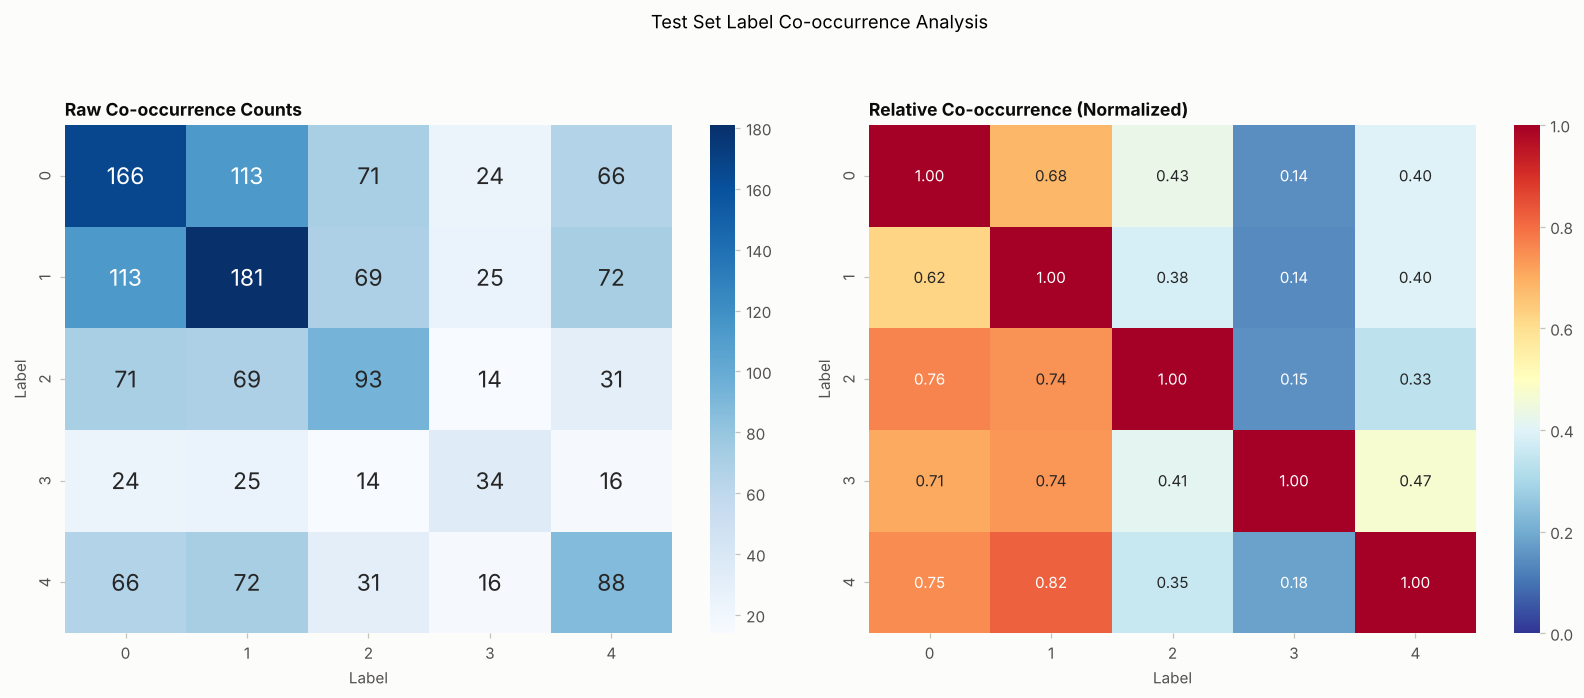

In [23]:
# BOOK CODE: Multilabel classification concepts -- visualizing results (pp. 146-148)
# The printed listing misses a comma after annot_kws in the second heatmap (a SyntaxError);
# this is the official notebook's version, which has the comma and a font size of 10 there.

# Create a detailed label co-occurrence visualization
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    # Compute raw co-occurrence counts
    cooccurrence = y.T @ y

    # Compute relative co-occurrence (normalized by diagonal)
    # This shows what percentage of time label i occurs with label j
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Plot raw co-occurrence
    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues',
                ax=ax1, annot_kws={"fontsize": 15})
    ax1.set_title('Raw Co-occurrence Counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    # Plot relative co-occurrence
    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f',
                cmap='RdYlBu_r', ax=ax2, annot_kws={"fontsize": 10},
                vmin=0, vmax=1)
    ax2.set_title('Relative Co-occurrence (Normalized)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')

    plt.suptitle(title, y=1.05)
    plt.tight_layout()

    # Print additional statistics
    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        percentage = count / len(y) * 100
        print(f"Label {i}: {count} samples ({percentage:.1f}%)")

    print("\nMost common label combinations:")
    # Get unique combinations and their counts
    unique_combinations = np.unique(y, axis=0, return_counts=True)
    sorted_idx = np.argsort(-unique_combinations[1])  # Sort by count (descending)
    for combo, count in zip(unique_combinations[0][sorted_idx][:5],
                            unique_combinations[1][sorted_idx][:5]):
        percentage = count / len(y) * 100
        print(f"Combination {combo}: {count} samples ({percentage:.1f}%)")

# Use the function on your test data
plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

**Output analysis.**

* **The statistics match the book exactly:**
  * 300 test samples, with label frequencies 166, 181, 93, 34 and 88;
  * the same five most common combinations, starting with **52 samples (17.3%) that have no label at all**.

  The dataset is fully determined by `random_state`.
* **The classification report** (one row per label):
  * The two frequent labels are predicted well (F1 0.81 for label 0 and 0.82 for label 1).
  * The rarer labels are mostly missed: recall **0.33** for label 2 and **0.18** for label 3, which only 34 test samples carry.
  * The micro-averaged F1 (all decisions pooled) is 0.70, while the macro average (each label counts equally) falls to 0.58 because of the rare labels.
  * The book computes `accuracy` but never prints it; extra (b) does.
* **Reading the relative matrix.** The code divides each **row** $i$ by the count of label $i$, so cell $(i, j)$ is $P(\text{label } j \mid \text{label } i)$, the share of samples with label $i$ that also carry label $j$.
  * This is how the book's "reading the matrices" paragraph describes it. Its earlier sentence ("what percentage of time label $i$ occurs when label $j$ is present") describes the transpose.
  * The matrix is not symmetric. Of the 34 samples with label 3, 71% also carry label 0, while only 14% of the 166 samples with label 0 carry label 3.
* **Labels 0 and 1** dominate the columns of the relative matrix (0.62 to 0.82 in every row). Part of this is simply their frequency, 55% and 60% of the samples: any label would often appear with them. Extra (c) separates real dependence from frequency.

In [24]:
# EXTRA: (a) The book's loop is binary relevance -- MultiOutputClassifier and OneVsRestClassifier give the same predictions
from sklearn.multioutput import MultiOutputClassifier
from sklearn.multiclass import OneVsRestClassifier

multi_output = MultiOutputClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
one_vs_rest = OneVsRestClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
print("loop == MultiOutputClassifier:", np.array_equal(y_pred, multi_output.predict(X_test)))
print("loop == OneVsRestClassifier  :", np.array_equal(y_pred, one_vs_rest.predict(X_test)))
print("\nthe features are word counts:", np.array_equal(X, np.round(X)), f"(values from {X.min():.0f} to {X.max():.0f})")
print("number of labels per sample (all 1000):", dict(enumerate(np.bincount(y.sum(axis=1)))))

loop == MultiOutputClassifier: True
loop == OneVsRestClassifier  : True

the features are word counts: True (values from 0 to 13)
number of labels per sample (all 1000): {0: np.int64(148), 1: np.int64(282), 2: np.int64(258), 3: np.int64(178), 4: np.int64(100), 5: np.int64(34)}


In [25]:
# EXTRA: (b) Multilabel metrics -- what "accuracy" means here, and the effect of zero_division
from sklearn.metrics import hamming_loss, f1_score, precision_recall_fscore_support

print(f"subset accuracy (the book's `accuracy`) : {accuracy:.3f}")
print(f"Hamming loss                             : {hamming_loss(y_test, y_pred):.3f}")
print(f"micro F1 / macro F1                      : {f1_score(y_test, y_pred, average='micro'):.3f} / "
      f"{f1_score(y_test, y_pred, average='macro'):.3f}")

no_true = y_test.sum(axis=1) == 0
no_pred = y_pred.sum(axis=1) == 0
print(f"\ntest samples without any true label: {no_true.sum()}, predicted without any label: {no_pred.sum()}, both: {(no_true & no_pred).sum()}")
for zero_division in (0, 1):
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average='samples', zero_division=zero_division)
    print(f"'samples avg' with zero_division={zero_division}: precision {p:.3f}, recall {r:.3f}, F1 {f:.3f}")

print("\n" + pd.DataFrame({
    "true count": y_test.sum(axis=0), "predicted count": y_pred.sum(axis=0),
}, index=[f"label {j}" for j in range(5)]).T.to_string())
print("\nlabels per test sample:", "true", np.bincount(y_test.sum(axis=1), minlength=6),
      "| predicted", np.bincount(y_pred.sum(axis=1), minlength=6))

subset accuracy (the book's `accuracy`) : 0.340
Hamming loss                             : 0.209
micro F1 / macro F1                      : 0.701 / 0.577

test samples without any true label: 52, predicted without any label: 20, both: 18
'samples avg' with zero_division=0: precision 0.721, recall 0.609, F1 0.620
'samples avg' with zero_division=1: precision 0.787, recall 0.782, F1 0.680

                 label 0  label 1  label 2  label 3  label 4
true count           166      181       93       34       88
predicted count      167      191       46        8       73

labels per test sample: true [52 70 84 61 24  9] | predicted [ 20 120 120  35   5   0]


In [26]:
# EXTRA: (c) Label dependence (lift) and classifier chains
from sklearn.multioutput import ClassifierChain

p_label = y_test.mean(axis=0)
p_joint = (y_test.T @ y_test) / len(y_test)
lift = p_joint / np.outer(p_label, p_label)
np.fill_diagonal(lift, np.nan)
print("lift P(i and j) / (P(i) P(j)) on the test set (1 = independent):")
print(pd.DataFrame(lift, index=range(5), columns=range(5)).round(2).to_string())

def multilabel_scores(name, predicted):
    print(f"{name:32s} subset accuracy {accuracy_score(y_test, predicted):.3f} | "
          f"Hamming loss {hamming_loss(y_test, predicted):.3f} | micro F1 {f1_score(y_test, predicted, average='micro'):.3f}")

print()
multilabel_scores("binary relevance (book)", y_pred)
chain_probas = []
for seed in range(10):
    chain = ClassifierChain(LogisticRegression(solver='liblinear'), order='random', random_state=seed).fit(X_train, y_train)
    chain_probas.append(chain.predict_proba(X_test))
    if seed == 0:
        multilabel_scores("one chain (random order)", chain.predict(X_test))
multilabel_scores("ensemble of 10 chains", (np.mean(chain_probas, axis=0) >= 0.5).astype(int))

lift P(i and j) / (P(i) P(j)) on the test set (1 = independent):
      0     1     2     3     4
0   NaN  1.13  1.38  1.28  1.36
1  1.13   NaN  1.23  1.22  1.36
2  1.38  1.23   NaN  1.33  1.14
3  1.28  1.22  1.33   NaN  1.60
4  1.36  1.36  1.14  1.60   NaN

binary relevance (book)          subset accuracy 0.340 | Hamming loss 0.209 | micro F1 0.701
one chain (random order)         subset accuracy 0.420 | Hamming loss 0.207 | micro F1 0.701
ensemble of 10 chains            subset accuracy 0.410 | Hamming loss 0.199 | micro F1 0.706


**Output analysis.**

* **(a)** The book's loop, `MultiOutputClassifier` and `OneVsRestClassifier` produce identical predictions: three spellings of binary relevance.
  * The book adds that `MultiOutputClassifier` "removes the need to select a solver specific to multilabel classification". In fact the solver is chosen in the same way, inside the wrapped estimator; the wrapper only saves the loop.
  * The features are integer word counts (0 to 13). The number of labels per sample ranges from 0 to 5, and 148 of the 1,000 samples have none.
* **(b) The book's `accuracy` is a subset accuracy of 0.34.** Only a third of the test samples get all five labels right. The Hamming loss of 0.21 says that about one label decision in five is wrong.
  * `zero_division=1` **flatters the "samples avg" row**. The 52 test samples without labels have an undefined recall, which becomes 1. Of these, 18 are also predicted empty, so their precision becomes 1 too.
  * With `zero_division=0` the samples-averaged recall drops from 0.782 to 0.609.
  * The model is **too cautious**. It predicts label 3 only 8 times (34 true) and label 2 46 times (93 true), and it gives only 5 test samples four labels and none five, although 33 have four or more. The 0.5 threshold of a per-label logistic regression rarely fires for a rare label.
* **(c) Lift** compares co-occurrence with what independence would give.
  * Every pair has a lift above 1: the labels are positively dependent, as the generator implies.
  * The strongest dependence links labels 3 and 4 (lift 1.60). Labels 0 and 1, the pair the book singles out, have the *weakest* (1.13): they co-occur most often because both are frequent, not because they depend on each other.
* **Classifier chains** exploit the dependence. One chain raises the subset accuracy from **0.34 to 0.42**, and an ensemble of 10 chains reaches 0.41 with the lowest Hamming loss (0.199). Label-by-label quality (micro F1) barely changes.
  * Chains help with getting the **whole set** right, which is what subset accuracy rewards.

---
## 5. Model evaluation metrics

### Summary

* This recipe evaluates logistic regression with the metrics met in Chapter 4: **precision, recall, F1-score and ROC curves**.
* **Getting ready** — the Breast Cancer data, split 70/30 (`random_state=2024`), this time *without* scaling.
* **How to do it:**
  * Fit `LogisticRegression(solver='liblinear')` and get both `predict` and `predict_proba`.
  * Print accuracy **0.94**, precision **0.94**, recall **0.95**, F1 **0.95** and ROC AUC **0.99**, and the classification report (Figure 6.12): "most of our performance metrics are comparable".
  * Plot the ROC curve with the diagonal of a random classifier (Figure 6.13): "a fairly solid performance".
* **How it works** — the definitions:
  * **accuracy** — overall correctness;
  * **precision** — the share of positive identifications that are correct;
  * **recall** — the share of actual positives that are found;
  * **F1** — the harmonic mean of precision and recall;
  * **ROC curve** — the true positive rate against the false positive rate across thresholds;
  * **AUC** — the overall ability to discriminate between the classes.
* **There's more** — the choice of metric depends on the goal: precision when false positives are costly, recall when as many positives as possible must be caught.

### Theory: thresholds, the ROC curve and the meaning of the AUC

**The confusion matrix depends on two choices:** which class is called *positive*, and the threshold $t$ applied to the predicted probability. For a positive class and a threshold:

| | predicted positive | predicted negative |
|---|---|---|
| **actually positive** | TP | FN |
| **actually negative** | FP | TN |

$$
\text{precision} = \frac{TP}{TP + FP}, \quad
\text{recall} = TPR = \frac{TP}{TP + FN}, \quad
FPR = \frac{FP}{FP + TN}, \quad
F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}} .
$$

Recall is also called *sensitivity*, and $1 - FPR$ is the *specificity*. scikit-learn's metrics use `pos_label=1` by default, which is **benign** in this dataset; the cancer-detection view needs `pos_label=0`.

**The ROC curve** traces $(FPR(t), TPR(t))$ as the threshold $t$ moves from 1 to 0, and does not depend on any single threshold.

**The AUC** has an exact probabilistic meaning. It is the probability that a randomly chosen positive sample receives a higher score than a randomly chosen negative one (ties count one half):

$$
\text{AUC} = P\big(s(x^+) > s(x^-)\big) .
$$

This is the Mann–Whitney $U$ statistic, rescaled. Consequences:

* the AUC only depends on the **ranking** of the scores, not on their calibration;
* swapping the roles of the classes (and using $1 - p$ as the score) leaves it unchanged;
* an AUC of 0.5 is random ranking, and 1 is perfect separation.

**Precision–recall curves** and their summary, the *average precision*, focus on the positive class. They are more informative than ROC curves when positives are rare.

**Choosing a threshold** is a separate decision from fitting the model. It should be made on validation data (for example, cross-validated predictions on the training set), never on the test set that reports the final performance.

In [27]:
# BOOK CODE: Model evaluation metrics -- getting ready (pp. 150-151)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    precision_score, recall_score,
    f1_score, roc_curve, auc
)
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report
              precision    recall  f1-score   support

           0       0.92      0.91      0.92        67
           1       0.94      0.95      0.95       104

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



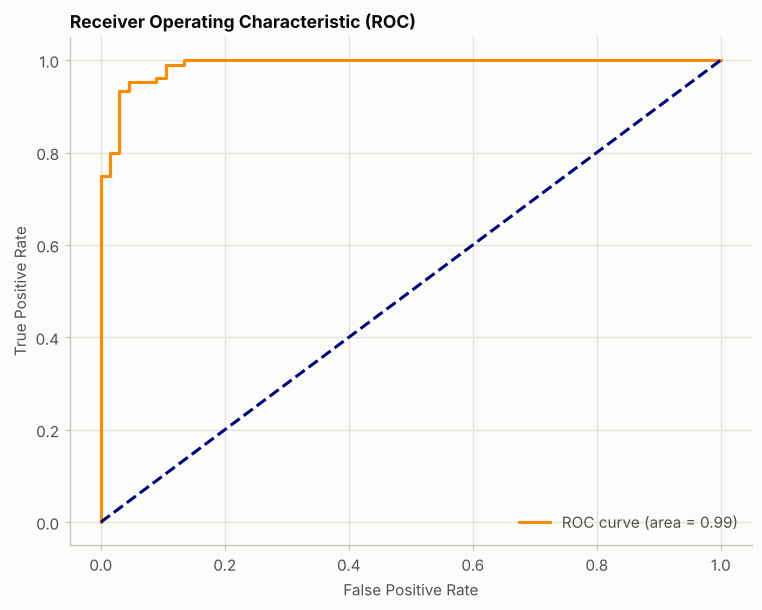

In [28]:
# BOOK CODE: Model evaluation metrics -- how to do it (pp. 151-153)
# Load the model
model = LogisticRegression(solver='liblinear')

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
report = classification_report(y_test, y_pred)

# Print the metrics
print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report")
print(report)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy',
         lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Output analysis.**

* **All five printed metrics match the book:** accuracy 0.94, precision 0.94, recall 0.95, F1 0.95, ROC AUC 0.99. The exact values are 0.936, 0.943, 0.952, 0.947 and 0.989. The official notebook shows the report as a styled table with `zero_division=1`, while the printed listing prints the plain text report reproduced here; the numbers are the same.
* **Behind the numbers** (171 test tumours: 67 malignant, 104 benign):
  * 61 malignant tumours are recognized and **6 are called benign**;
  * 99 benign tumours are recognized and 5 are flagged as malignant.
* **These precision, recall and F1 values are about the benign class**, label 1 and scikit-learn's default positive class. "Recall 0.95" means that 95% of the *benign* tumours are recognized. For screening, the relevant figure is the recall of the malignant class, $61/67 = 0.910$: one cancer in eleven is missed. Extra (a) computes the metrics from that point of view.
* **The ROC curve** hugs the upper-left corner (AUC 0.989), but the model's default threshold of 0.5 is only one point on it. Extra (b) moves along the curve.

In [29]:
# EXTRA: (a) The same model seen from the malignant side, and the AUC as a ranking probability
from sklearn.metrics import roc_auc_score, average_precision_score

print("Malignant as the positive class (pos_label=0):")
print(f"  precision {precision_score(y_test, y_pred, pos_label=0):.3f}, recall {recall_score(y_test, y_pred, pos_label=0):.3f}, "
      f"F1 {f1_score(y_test, y_pred, pos_label=0):.3f}")
print(f"ROC AUC with benign as positive    : {roc_auc_score(y_test, y_prob):.4f}")
print(f"ROC AUC with malignant as positive : {roc_auc_score(1 - y_test, 1 - y_prob):.4f}")

benign_scores, malignant_scores = y_prob[y_test == 1], y_prob[y_test == 0]
pairs_right = (benign_scores[:, None] > malignant_scores[None, :]).mean()
pairs_tied = (benign_scores[:, None] == malignant_scores[None, :]).mean()
print(f"share of the {benign_scores.size * malignant_scores.size} (benign, malignant) pairs ranked correctly: "
      f"{pairs_right + 0.5 * pairs_tied:.4f}")
print(f"\naverage precision: benign as positive {average_precision_score(y_test, y_prob):.3f}, "
      f"malignant as positive {average_precision_score(1 - y_test, 1 - y_prob):.3f}")

Malignant as the positive class (pos_label=0):
  precision 0.924, recall 0.910, F1 0.917
ROC AUC with benign as positive    : 0.9892
ROC AUC with malignant as positive : 0.9892
share of the 6968 (benign, malignant) pairs ranked correctly: 0.9892

average precision: benign as positive 0.993, malignant as positive 0.986


In [30]:
# EXTRA: (b) Choosing a threshold for screening -- chosen on cross-validated training predictions, checked on the test set
from sklearn.model_selection import cross_val_predict, StratifiedKFold

p_malignant_cv = cross_val_predict(LogisticRegression(solver='liblinear'), X_train, y_train,
                                   cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 0]
p_malignant_test = 1 - y_prob
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    flagged_cv, flagged_test = p_malignant_cv >= t, p_malignant_test >= t
    rows.append({
        "threshold on P(malignant)": t,
        "CV recall (malignant)": flagged_cv[y_train == 0].mean().round(3),
        "CV false-alarm rate": flagged_cv[y_train == 1].mean().round(3),
        "test: malignant caught": f"{flagged_test[y_test == 0].sum()} / {(y_test == 0).sum()}",
        "test: benign flagged": f"{flagged_test[y_test == 1].sum()} / {(y_test == 1).sum()}",
    })
print(pd.DataFrame(rows).to_string(index=False))

 threshold on P(malignant)  CV recall (malignant)  CV false-alarm rate test: malignant caught test: benign flagged
                       0.5                  0.924                0.024                61 / 67              5 / 104
                       0.4                  0.945                0.032                62 / 67              5 / 104
                       0.3                  0.945                0.036                64 / 67              7 / 104
                       0.2                  0.972                0.047                65 / 67              9 / 104
                       0.1                  0.986                0.119                65 / 67             19 / 104


accuracy over 200 splits: mean 0.949, std 0.015, range 0.912 to 0.982
ROC AUC over 200 splits : mean 0.990, std 0.006, minimum 0.963
splits scoring lower than the book's split (0.936): 12%

book's split, standardized features + lbfgs: accuracy 0.982, ROC AUC 0.999


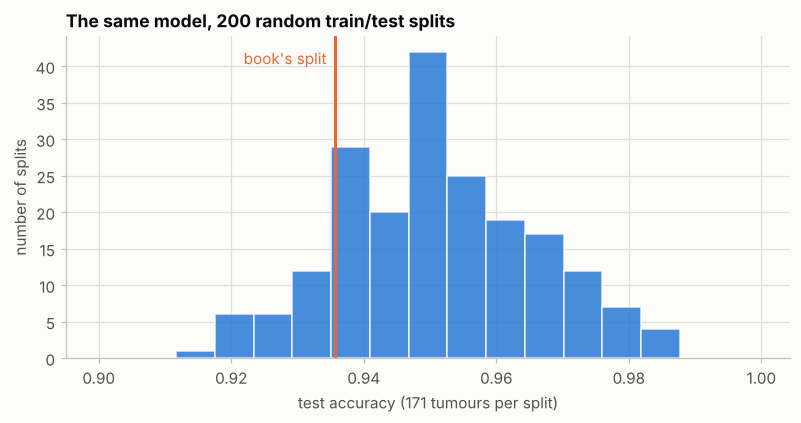

In [31]:
# EXTRA: (c) One split is one draw -- the same model over 200 random splits
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

accuracies, aucs = [], []
for seed in range(200):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=seed)
    fitted = LogisticRegression(solver='liblinear').fit(Xa, ya)
    accuracies.append(fitted.score(Xb, yb))
    aucs.append(roc_auc_score(yb, fitted.predict_proba(Xb)[:, 1]))
accuracies, aucs = np.array(accuracies), np.array(aucs)
print(f"accuracy over 200 splits: mean {accuracies.mean():.3f}, std {accuracies.std():.3f}, "
      f"range {accuracies.min():.3f} to {accuracies.max():.3f}")
print(f"ROC AUC over 200 splits : mean {aucs.mean():.3f}, std {aucs.std():.3f}, minimum {aucs.min():.3f}")
print(f"splits scoring lower than the book's split ({accuracy:.3f}): {np.mean(accuracies < accuracy - 1e-12):.0%}")

scaled = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
print(f"\nbook's split, standardized features + lbfgs: accuracy {scaled.score(X_test, y_test):.3f}, "
      f"ROC AUC {roc_auc_score(y_test, scaled.predict_proba(X_test)[:, 1]):.3f}")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
bins = np.arange(0.9, 1.0001, 1 / 171)
ax.hist(accuracies, bins=bins, color=PALETTE[0], alpha=0.85, edgecolor=SURFACE)
ax.axvline(accuracy, color=PALETTE[1], lw=2)
ax.text(accuracy, 0.96, "book's split  ", color=PALETTE[1], transform=ax.get_xaxis_transform(), va="top", ha="right")
ax.set_xlabel("test accuracy (171 tumours per split)")
ax.set_ylabel("number of splits")
ax.set_title("The same model, 200 random train/test splits")
plt.show()

**Output analysis.**

* **(a) From the malignant side** the same predictions give precision 0.924, recall **0.910** and F1 0.917: lower than the benign-side figures the book prints.
  * The ROC AUC is identical from both sides (0.989), and it equals the share of the 6,968 (benign, malignant) pairs that the model ranks correctly. The AUC is a ranking statistic, as the theory section says.
  * The average precision is lower for the malignant class (0.986 against 0.993), because malignant tumours are the minority.
* **(b) Lowering the threshold trades false alarms for caught cancers.** The thresholds are judged on cross-validated predictions of the training set, then checked on the test set.
  * Flagging a tumour as malignant when $P(\text{malignant}) \ge 0.2$ raises the cross-validated recall from 0.924 to 0.972, for a false-alarm rate of 4.7% instead of 2.4%.
  * On the test set this catches **65 of the 67** malignant tumours instead of 61, at the cost of 9 benign tumours flagged instead of 5.
  * Going down to 0.1 adds false alarms (19) without catching more on this test set.
  * Which trade-off is right is a medical decision, not a statistical one. The metrics only make the trade-off visible.
* **(c) The book's 0.94 is a single draw.** Over 200 random splits the same model averages **0.949** (standard deviation 0.015, from 0.912 to 0.982), and the ROC AUC averages 0.990. The book's split is on the low side: only 12% of the splits score lower.
  * Standardizing the features (and using the default `lbfgs` solver) raises the accuracy on the book's split to **0.982** and the AUC to 0.999.
  * As in recipe 1, unscaled features handicap a penalized model, and `liblinear` also penalizes the intercept.

---
## 6. Practical exercises with advanced logistic regression

### Summary

The chapter closes with three exercises (p. 155), each described as a list of steps; the solutions are in the book's repository.

1. **Building a regularized logistic regression model** (the official notebook calls it "Implementing Ridge Regression"): on the Breast Cancer data, "applying both Lasso and Ridge", although the steps and the solution only fit the Lasso model.
2. **Evaluating multiclass logistic regression** — a multinomial model on Iris.
3. **Visualizing logistic regression results** — the decision boundary of a logistic regression on a synthetic two-feature dataset (`make_classification`), drawn on a mesh grid.

The official solutions print accuracies of 0.95 and 0.93 and draw one figure. Exercises 1 and 2 call `accuracy_score` without importing it (they relied on an earlier cell); the import is added below.

### Theory: what the exercises show

* **Exercise 1** fits an $L_1$ model with `C=0.1` on **unscaled** features. The penalty $\lVert w \rVert_1$ charges a feature according to the size of its coefficient. A feature measured in large units (areas in the hundreds or thousands) needs only a tiny coefficient to have a large effect, so the $L_1$ penalty barely charges it and **prefers large-scale features**, whatever their medical relevance. Extra (a) shows the selected features and adds the ridge half of the exercise.
* **Exercise 2** is recipe 2's multinomial model on the same split, so it must give the same accuracy.
* **Exercise 3** — with two features, the decision boundary $w_1 x_1 + w_2 x_2 + b = 0$ is a straight line, $x_1 = -(w_2 x_2 + b)/w_1$. The probability $\sigma(w_1 x_1 + w_2 x_2 + b)$ is constant along every line parallel to it, so the probability contours are parallel bands. Their spacing shrinks as $\lVert w \rVert$ grows.

In [32]:
# BOOK CODE: Exercise 1 -- building a regularized logistic regression model (official solution)
#Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score  # missing in the official solution
import pandas as pd

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Lasso regularized Logistic Regression model
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=10000, C=0.1)
lasso_model.fit(X_train, y_train)

# Make predictions with the Lasso model
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the Lasso model performance
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
print(f"Lasso Model Accuracy: {accuracy_lasso:.2f}")

Lasso Model Accuracy: 0.95


In [33]:
# BOOK CODE: Exercise 2 -- evaluating multiclass logistic regression (official solution)
# Load the libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score  # missing in the official solution

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Multinomial Logistic Regression model
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

# Make predictions with the Multinomial model
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluate the Multinomial model performance
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print(f"Multinomial Model Accuracy: {accuracy_multinomial:.2f}")

Multinomial Model Accuracy: 0.93


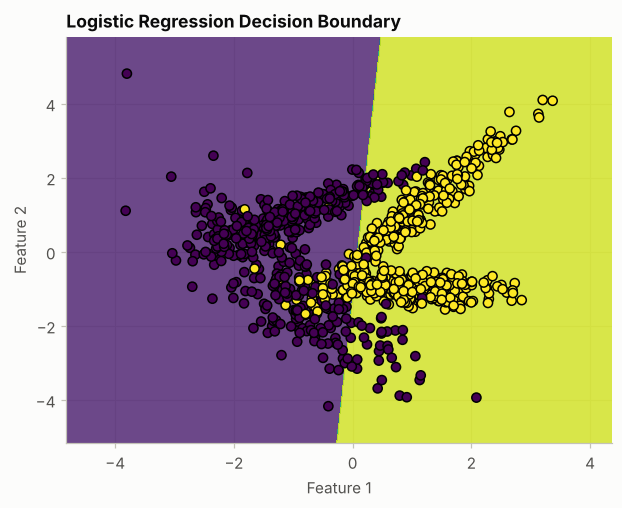

In [34]:
# BOOK CODE: Exercise 3 -- visualizing logistic regression results (official solution)
# Load libraries for visualization and dataset creation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Create synthetic dataset for binary classification
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Logistic Regression model
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class probabilities across the grid
Z = logistic_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Output analysis.**

* **Exercise 1:** "Lasso Model Accuracy: 0.95", as in the official notebook. The exact value is 0.947.
* **Exercise 2:** "Multinomial Model Accuracy: 0.93", as in the official notebook. It is recipe 2's multinomial model, 42 of 45 flowers.
* **Exercise 3:** the plot shows the two classes (purple and yellow in Matplotlib's default colour map) separated by a straight, almost vertical line. The comment says "predict class probabilities", but the solution calls `predict`, so the background shows only the two predicted labels. Extra (b) draws the probabilities. The grid step of 0.01 means about a million predictions for one picture.

In [35]:
# EXTRA: (a) Exercise 1 completed -- the unscaled Lasso's choice of features, and ridge versus Lasso, scaled versus not
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Xc, yc = load_breast_cancer(return_X_y=True)
print("features kept by the unscaled Lasso (C=0.1):", list(data.feature_names[lasso_model.coef_[0] != 0]))

cv10 = StratifiedKFold(10, shuffle=True, random_state=0)
candidates = {
    "Lasso, raw features (exercise)": LogisticRegression(**L1, solver='liblinear', max_iter=10000, C=0.1),
    "ridge, raw features":            LogisticRegression(**L2, solver='liblinear', max_iter=10000, C=0.1),
    "Lasso, standardized":            make_pipeline(StandardScaler(), LogisticRegression(**L1, solver='liblinear', C=0.1)),
    "ridge, standardized":            make_pipeline(StandardScaler(), LogisticRegression(**L2, solver='liblinear', C=0.1)),
}
for name, estimator in candidates.items():
    s = cross_val_score(estimator, Xc, yc, cv=cv10)
    print(f"{name:32s}: 10-fold CV accuracy {s.mean():.3f} (std {s.std():.3f})")

features kept by the unscaled Lasso (C=0.1): [np.str_('mean perimeter'), np.str_('mean area'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area')]
Lasso, raw features (exercise)  : 10-fold CV accuracy 0.930 (std 0.035)
ridge, raw features             : 10-fold CV accuracy 0.944 (std 0.017)
Lasso, standardized             : 10-fold CV accuracy 0.972 (std 0.014)
ridge, standardized             : 10-fold CV accuracy 0.981 (std 0.017)


boundary: 2.283 * x1 + (-0.154) * x2 + (-0.183) = 0   ->   x1 = 0.080 + 0.068 * x2
accuracy: train 0.866, test 0.897


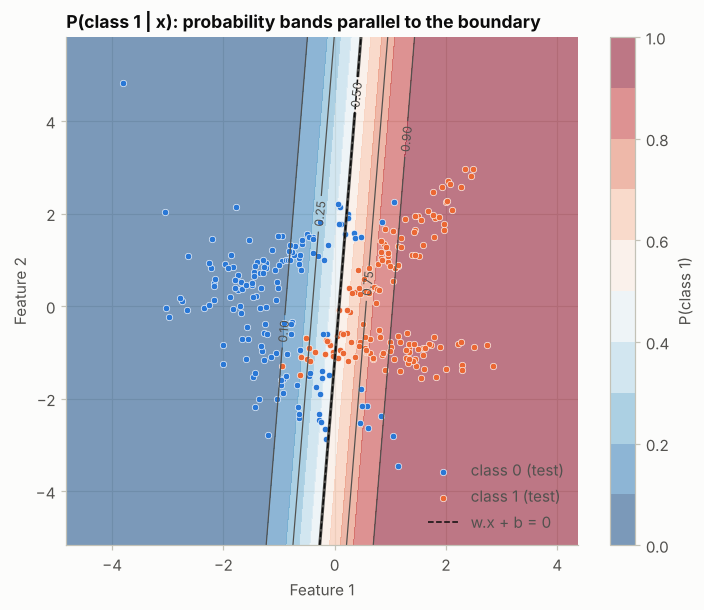

In [36]:
# EXTRA: (b) Exercise 3 with probabilities -- parallel probability bands around the boundary line
w1, w2 = logistic_model.coef_[0]
b0 = logistic_model.intercept_[0]
print(f"boundary: {w1:.3f} * x1 + ({w2:.3f}) * x2 + ({b0:.3f}) = 0   ->   x1 = {-b0 / w1:.3f} + {-w2 / w1:.3f} * x2")
print(f"accuracy: train {logistic_model.score(X_train, y_train):.3f}, test {logistic_model.score(X_test, y_test):.3f}")

gx, gy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
P = logistic_model.predict_proba(np.c_[gx.ravel(), gy.ravel()])[:, 1].reshape(gx.shape)

fig, ax = plt.subplots(figsize=(7.5, 6))
filled = ax.contourf(gx, gy, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.55)
lines = ax.contour(gx, gy, P, levels=[0.1, 0.25, 0.5, 0.75, 0.9], colors=INK_SOFT, linewidths=[0.8, 0.8, 2, 0.8, 0.8])
ax.clabel(lines, fmt="%.2f", fontsize=8)
for label, color, name in [(0, PALETTE[0], "class 0"), (1, PALETTE[1], "class 1")]:
    keep = y_test == label
    ax.scatter(X_test[keep, 0], X_test[keep, 1], s=18, color=color, edgecolor="white", lw=0.4, label=f"{name} (test)")
x2_line = np.array([y_min, y_max])
ax.plot(-(w2 * x2_line + b0) / w1, x2_line, color=INK, lw=1, ls="--", label="w.x + b = 0")
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("P(class 1 | x): probability bands parallel to the boundary")
fig.colorbar(filled, ax=ax, label="P(class 1)")
ax.legend(loc="lower right")
plt.show()

**Output analysis.**

* **(a) Exercise 1 completed.** Without scaling, the Lasso keeps 7 features, and 5 of them are **areas and perimeters** (*mean perimeter*, *mean area*, *area error*, *worst perimeter*, *worst area*), besides *worst radius* and *worst texture*. These are the features with the largest numeric ranges, as the theory section predicts.
  * The scaled Lasso of recipe 3 picks concavity and texture features instead.
  * Ten-fold cross-validation ranks the four variants clearly:

    | Model | CV accuracy |
    |---|---|
    | Lasso, raw features | 0.930 |
    | ridge, raw features | 0.944 |
    | Lasso, standardized | 0.972 |
    | ridge, standardized | 0.981 |

    Standardizing matters more than the choice of penalty. The exercise's 0.95 on one split hides that its model is the weakest of the four.
* **(b) The probability picture** shows what the exercise's two-colour plot hides:
  * The 0.5 contour coincides with the dashed line $w^\top x + b = 0$. With $w_1 = 2.28$ and $w_2 = -0.15$, it is almost vertical ($x_1 \approx 0.08 + 0.07\, x_2$): feature 1 carries nearly all the information.
  * The other contours are parallel lines; between 0.1 and 0.9 the probability changes over a band about two units wide.
  * The overlap of the two clouds limits the accuracy to 0.87 on the training set and 0.90 on the test set.

---
## Decision guide: setting up a logistic regression

| Situation | Choice | Notes |
|---|---|---|
| Binary classification with interpretable probabilities | `make_pipeline(StandardScaler(), LogisticRegression())` | the default `C=1` is already an $L_2$ penalty; tune `C` |
| Three or more mutually exclusive classes | `LogisticRegression()` (multinomial for every solver except `liblinear`) | better probabilities than OvR, similar accuracy |
| One-vs-rest is required (for example, the `liblinear` solver) | `OneVsRestClassifier(LogisticRegression(solver='liblinear'))` | `liblinear` refuses three or more classes since 1.8 |
| Many features, a sparse model wanted | `l1_ratio=1` (`penalty='l1'` before 1.8) with `liblinear` or `saga` | standardize first; among correlated features it keeps one |
| Correlated groups of features to keep together | `solver='saga'`, `0 < l1_ratio < 1` (elastic net) | standardize; tune `C` and `l1_ratio` |
| Several labels per sample | `MultiOutputClassifier` or `OneVsRestClassifier` (binary relevance), `ClassifierChain` | report subset accuracy *and* Hamming loss |
| Missing one class is much worse than a false alarm | a threshold on `predict_proba`, chosen by cross-validation | report the recall of the class that matters (`pos_label`) |
| Imbalanced classes | `class_weight='balanced'`, precision–recall curve, average precision | accuracy and ROC AUC can look good while the minority class is missed |

## Chapter summary and key takeaways

| Recipe | Main tools | Key idea |
|---|---|---|
| Overview of logistic regression | `LogisticRegression`, `confusion_matrix`, `classification_report` | A sigmoid of a linear score; the log-odds are linear, and the log-loss is minimized numerically |
| Multiclass techniques | `OneVsRestClassifier`, multinomial `LogisticRegression` | OvR fits one model per class; softmax fits them jointly and gives better probabilities |
| Regularization | `C`, `l1_ratio` (`penalty`), `liblinear`, `saga` | `C` is the inverse penalty strength; $L_1$ selects features, $L_2$ shrinks them; scale first |
| Multilabel concepts | `MultiOutputClassifier`, `ClassifierChain`, `hamming_loss` | Binary relevance ignores label dependencies; chains use them; subset accuracy is strict |
| Evaluation metrics | `precision_score`, `recall_score`, `roc_curve`, `roc_auc_score` | Metrics depend on the positive class and the threshold; the AUC is a ranking probability |
| Practical exercises | `LogisticRegression`, `make_classification` | Without scaling, $L_1$ picks features by their units; the 2-D boundary is a straight line |

**Key takeaways**

1. Logistic regression is a linear model for the **log-odds**, fitted by penalized maximum likelihood. scikit-learn's default is already regularized (`C=1`), so scaling the features changes the model, not only the speed of the solver.
2. For three or more classes, `LogisticRegression` fits the multinomial (softmax) model, the only built-in option since scikit-learn 1.8 (one-vs-rest needs `OneVsRestClassifier`). It matches OvR in accuracy on Iris and gives much better probabilities.
3. `C` is the **inverse** of the penalty strength. $L_1$ (`l1_ratio=1`) removes features and keeps one from each group of correlated features; $L_2$ shrinks them all. Tune `C` by cross-validation on standardized features.
4. Multilabel problems need multilabel metrics. Subset accuracy and Hamming loss tell different stories, and `zero_division=1` can flatter a report. Classifier chains help when the labels depend on each other.
5. Read precision and recall for the class that matters. In scikit-learn's breast cancer data, label 1 is *benign*. Choose the decision threshold on validation data, and remember that one train/test split is only one draw.

**Book (scikit-learn 1.5) vs. the version used here — notes from the reproduction**

* **Two listings fail on scikit-learn 1.9**, both in recipe 2:
  * `LogisticRegression(solver='liblinear')` on three classes raises a `ValueError` since 1.8. The notebook wraps it in `OneVsRestClassifier`, which reproduces the old internal OvR.
  * `multi_class='multinomial'` raises a `TypeError` since 1.8 (the book announces its removal "after version 1.7"). The notebook drops it, as the official notebook does; the multinomial model is the default anyway.
* **`penalty='l1'` / `penalty='l2'`** (recipe 3 and exercise 1) still work on 1.9 but are deprecated since 1.8 and will be removed in 1.10. The replacement is `l1_ratio=1` / `l1_ratio=0`, and extra 3(a) shows that the models are identical. The setup cell silences the two deprecation warnings, and the extra code uses `L1` and `L2`, which choose the right spelling for the installed version.
* All printed outputs reproduce: 0.95 (recipe 1), the label statistics of recipe 4, the five metrics of recipe 5, and 0.95 and 0.93 in the exercises. The styled classification reports contain random HTML ids, so their raw output changes from run to run, although the numbers do not.
* Small corrections to the listings: the printed recipe 1 uses `plt`, `sns` and `display` without importing the first two; the printed co-occurrence function misses a comma (the official version is used); the exercise solutions omit `import accuracy_score`.
* Precisions to the chapter text:
  * The logistic formula's exponent ends in "$\beta_n + X_n$"; it should read $\beta_n X_n$.
  * In recipe 2:
    * the "confusion matrix for OvR classification" is a classification report;
    * "macro accuracy" means the macro average;
    * Iris is a three-class problem, not "a binary classification problem";
    * the petal features have a *negative* excess kurtosis over all flowers (they are bimodal), and their value comes from the separation between classes.
  * In recipe 3, "ridge outperforms in precision while Lasso outperforms in recall" holds for the malignant class and is reversed for the benign class.
  * In recipe 4:
    * the relative co-occurrence matrix gives $P(j \mid i)$ in row $i$, and one sentence of the reading guide describes its transpose;
    * "binary relevance" is the strategy already used, not an alternative to it;
    * the book's `accuracy` is a subset accuracy that is computed but never printed.
  * In recipe 5, the printed precision, recall and F1 refer to the *benign* class, scikit-learn's default positive label in this dataset.

## References

1. Sukup, J. (2025). *scikit-learn Cookbook* (3rd ed.). Packt Publishing. Code repository: <https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition>
2. Cox, D. R. (1958). The regression analysis of binary sequences. *Journal of the Royal Statistical Society: Series B, 20*(2), 215–242.
3. Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). Wiley.
4. Fan, R.-E., Chang, K.-W., Hsieh, C.-J., Wang, X.-R., & Lin, C.-J. (2008). LIBLINEAR: A library for large linear classification. *Journal of Machine Learning Research, 9*, 1871–1874.
5. Liu, D. C., & Nocedal, J. (1989). On the limited memory BFGS method for large scale optimization. *Mathematical Programming, 45*, 503–528.
6. Rifkin, R., & Klautau, A. (2004). In defense of one-vs-all classification. *Journal of Machine Learning Research, 5*, 101–141.
7. Tsoumakas, G., & Katakis, I. (2007). Multi-label classification: An overview. *International Journal of Data Warehousing and Mining, 3*(3), 1–13.
8. Read, J., Pfahringer, B., Holmes, G., & Frank, E. (2011). Classifier chains for multi-label classification. *Machine Learning, 85*(3), 333–359.
9. Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874.
10. Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *Proceedings of SPIE 1905, Biomedical Image Processing and Biomedical Visualization*, 861–870.
11. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
12. scikit-learn documentation: [Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) · [Multiclass and multioutput algorithms](https://scikit-learn.org/stable/modules/multiclass.html) · [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html) · [`make_multilabel_classification`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_multilabel_classification.html)